In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pylab as plt
import matplotlib.dates as mdates
import seaborn as sns

from utils import*


# **A Guide to the `PRO-DMD-01` files**

In [2]:
PATH = '../../Desktop/data/CureDuchenne/Data/' #path to the data directory
files = os.listdir(PATH) #list all the files

print(f"There are {len(files)} csv files.")

There are 26 csv files.


In [3]:
dataframes = {} # a dictionary that has as key the name of the file and as value the content of the file as dataframe
keys = [] # a list of all the file names (keys to the dataframe dictionary)

for file in files:
    keys.append(file[:-4])
    dataframes[file[:-4]] = pd.read_csv(PATH+file, encoding_errors='ignore', low_memory=False)

In [4]:
print(keys) # print the available files

['pu', 'eg', 'ie', 'lb', 'qs', 'dm', 'bm', 'ae', 'sg', 'mh', 'co', 'cm', 'cv', 'ms', 'sc', 'dg', 'pe', 'ho', 'ds', 'il', 'tt', 'eurofins', 're', 'mt', 'sv', 'vs']


### **Timing: How is time counted in the CureDuchenne data?**
The columns `'STUDYID'`, `'DOMAIN'`, `'USUBJID'`, `'VISITNUM'`, `'VISIT'` are common for all files, except `eurofins.csv`.
<br>

| VARIABLE NAME | VARIABLE LABEL | TYPE | NOTES |
| -------- | ------------ | ---- | ----------------------------------------------------------------------------------------------------------------- |
| VISIT    | Visit Name   | Char | 1\. Protocol-defined description of clinical encounter.<br>2\. May be used in addition to VISITNUM and/or VISITDY |
| VISITNUM | Visit Number | Num  | 1\. Clinical encounter number.<br>2\. Numeric version of VISIT, used for sorting.


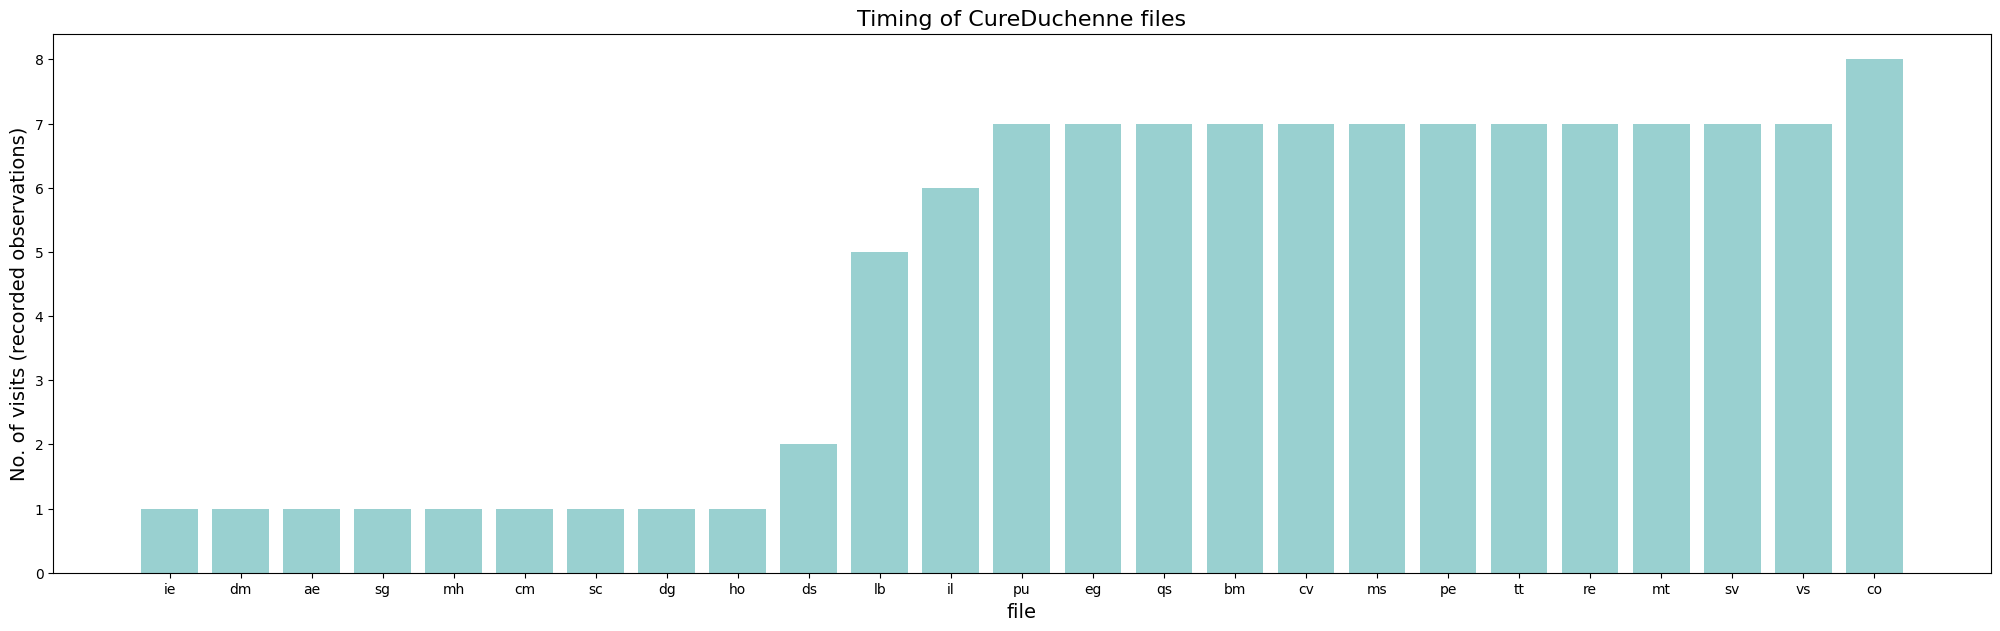

In [5]:
visits = {}
visits_count = {}

for key in keys:
    if key != 'eurofins':
        df = dataframes[key]
        if 'VISITNUM' in df.columns.to_list():
            visits[key] = set(df['VISITNUM'])
            visits_count[key] = len(set(df['VISITNUM']
                                       ))
        else:
            print(f"You have to check {key}.csv for documentation.")
            visits[key] = [()]
            visits_count[key] = 0

vc = visits_count.items()
vc = sorted(vc, key=lambda x:x[1])
x, y = zip(*vc)    
        
fig = plt.figure(figsize=(25,7))
plt.bar(x, y, color='darkcyan', alpha=0.4)
plt.xlabel("file", fontsize='14')
plt.ylabel("No. of visits (recorded observations)", fontsize='14')
plt.title("Timing of CureDuchenne files", fontsize='16')
plt.show()

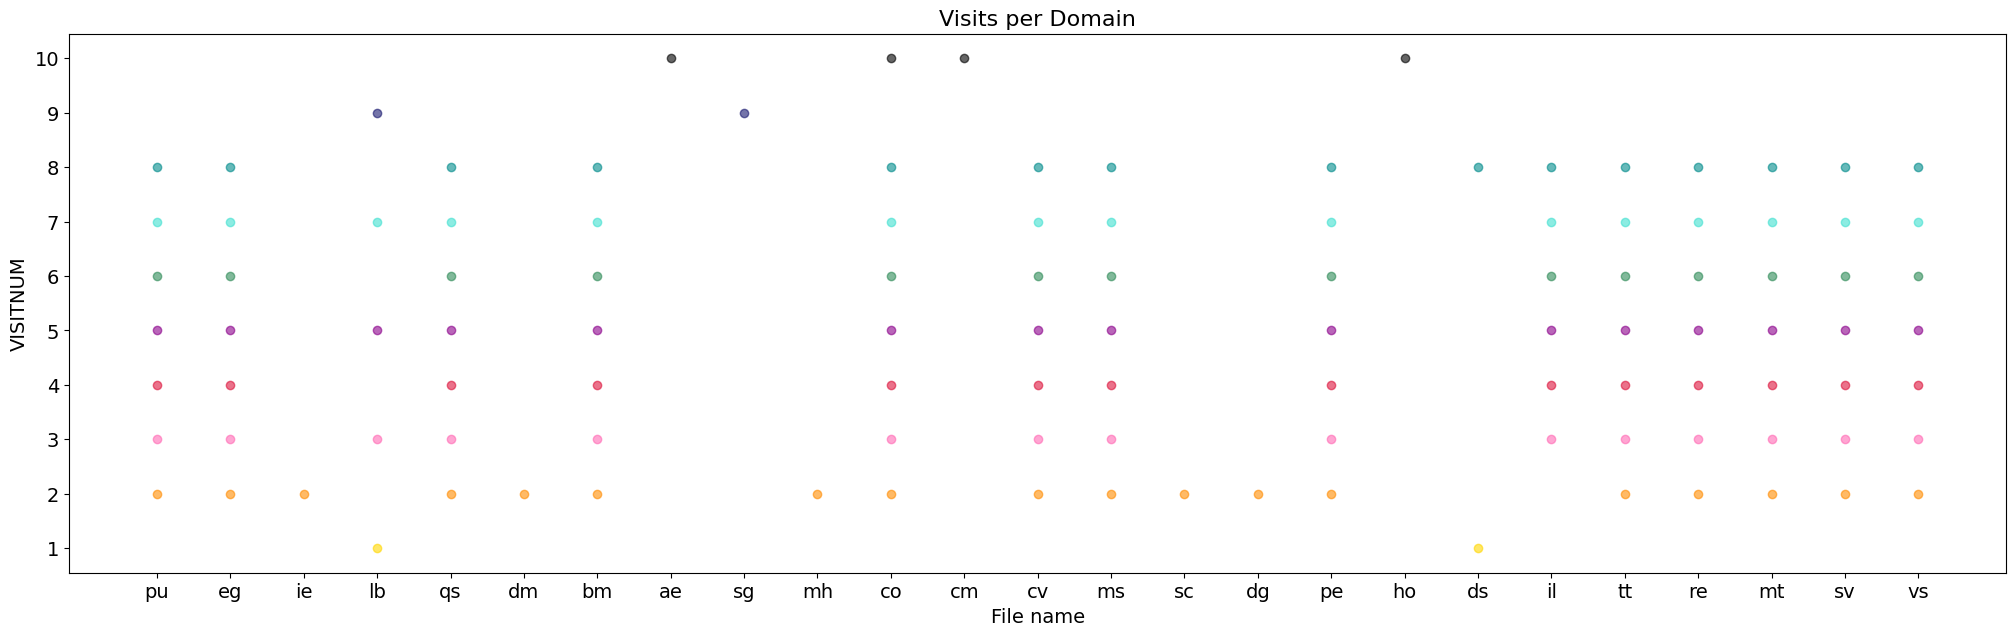

In [6]:
fig = plt.figure(figsize=(25,7))
plt.yticks([1, 2, 3, 4, 5, 6, 7, 8, 9, 10], fontsize=14)
plt.xticks(fontsize=14)
plt.xlabel('File name', fontsize=14)
plt.ylabel('VISITNUM', fontsize=14)
plt.title('Visits per Domain', fontsize=16)
for key in visits.keys():
    colors = ['gold', 'darkorange', 'hotpink', 'crimson', 'darkmagenta', 'seagreen', 'turquoise', 'darkcyan', 'midnightblue', 'black'] 
    if key!='eurofins':
        vs = list(visits[key])
        for i,v in enumerate(vs):
            plt.scatter(key, v, color=colors[v-1], alpha=0.6)

| VISIT | VISITNUM | 
| ---------- | -- | 
| SCREENING  | 1  | 
| DAY1       | 2  |
| MONTH6     | 3  |
| MONTH12    | 4  |
| MONTH18    | 5  |
| MONTH24    | 6  |
| MONTH30    | 7  |
| MONTH36    | 8  |
| SIGN       | 9  |
| COMMON CRF | 10 |

# **DEMOGRAPHICS & STATIC FEATURES**

# Files with 1 visit

# `ie.csv`

The `ie.csv`, coontains the information for the inclusion/exculsion criteria that have not met for the subjects. 

- *It contains only one observation for each subject.* 

In [ ]:
ie = dataframes['ie']
ie.head()

In [8]:
missing_values(ie)

,STUDYID,DOMAIN,USUBJID,VISITNUM,VISIT,IESEQ,IEELIG,IETESTCD,IETEST,IECAT,IEORRES,IESTRESC,IEYN,IEYNRSN
Total,0,0,0,0,0,0,0,268,268,268,268,268,268,268
Percent(%),0.0,0.0,0.0,0.0,0.0,0.0,0.0,98.892989,98.892989,98.892989,98.892989,98.892989,98.892989,98.892989
Types,object,object,object,int64,object,int64,object,object,object,object,object,object,object,object


In [ ]:
ie = cleaning_df(ie)
ie.head()

The `'IEELIG'` column refers to the eligibility of the subjects. All the subjects (269) are eligible and met all the inclusion criterion apart from one subject, that was eventually enrolled to the study:

In [ ]:
exception = ie.loc[ie['IEELIG']=='NO']
exception

By reviewing the `ie.csv` file, we note that there are 268 subjects, that met all the incllusion criteria and 1 subject that although it did not meet all the inclusion criteria, it was included in the study. To that end, there are overall **269 unique subjects**. We store the subject ids in the `subj_ids` list.

# `dm.csv`

The `dm.csv` contains the demographics of the subjects.

- *It contains only one observation for each subject.* 

In [ ]:
dm = dataframes['dm']
dm.head()

In [12]:
missing_values(dm)

,STUDYID,DOMAIN,USUBJID,VISITNUM,VISIT,BRTHDTC,SEX,RACE,ETHNIC,DMDNA,DMTECH,DMDNAOTH
Total,0,0,0,0,0,0,0,0,0,0,0,215
Percent(%),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,79.925651
Types,object,object,object,int64,object,object,object,object,object,object,object,object


In [ ]:
dm = dm.drop(['STUDYID', 'DOMAIN', 'DMDNA', 'SEX', 'VISIT', 'VISITNUM'], axis=1)
dm.head()

In [ ]:
dm = dm.replace({'RACE': {'NOT COLLECTED- AS PER LOCAL LAWS':'UNKNOWN', 
                          'WHITE - WHITE/CAUCASIAN/EUROPEAN HERITAGE': 'WHITE_EUROPEAN', 
                          'WHITE - ARABIC/NORTH AFRICAN HERITAGE': 'WHITE_ARABIC', 
                          'AFRICAN AMERICAN/AFRICAN HERITAGE': 'AFRICAN_AMERICAN', 
                          'AMERICAN INDIAN OR ALASKAN NATIVE': 'AMERICAN_INDIAN_ALASKAN', 
                          'ASIAN - CENTRAL/SOUTH ASIAN HERITAGE': 'CENTRAL_SOUTH_ASIAN', 
                          'ASIAN - EAST ASIAN HERITAGE': 'EAST_ASIAN', 
                          'ASIAN - JAPANESE HERITAGE':'JAPANESE'}})
dm.head()

In [15]:
dm.ETHNIC.value_counts()

NOT HISPANIC OR LATINO                 184
HISPANIC OR LATINO                      58
UNKNOWN                                 22
NA- NOT COLLECTED AS PER LOCAL LAWS      5
Name: ETHNIC, dtype: int64

In [ ]:
dm = dm.replace({'ETHNIC':{'NOT HISPANIC OR LATINO': 'NOT_HISPANIC_LATINO', 
                           'HISPANIC OR LATINO': 'HISPANIC_LATINO', 
                           'NA- NOT COLLECTED AS PER LOCAL LAWS': 'UNKNOWN'}})

dm.head()

In [17]:
dm.DMTECH.value_counts()

MLPA (MULTIPLEX LIGATION-DEPENDENT PROBE AMPLIFICATION)    194
OTHER                                                       54
CGH (COMPARATIVE GENOMIC HYBRIDISATION)                     21
Name: DMTECH, dtype: int64

In [ ]:
dm = dm.replace({'DMTECH':{'MLPA (MULTIPLEX LIGATION-DEPENDENT PROBE AMPLIFICATION)':'MLPA', 
                      'CGH (COMPARATIVE GENOMIC HYBRIDISATION)':'CGH'}})
dm.head()

In [19]:
dm.DMDNAOTH.unique()

array([nan, 'DHPLC', 'SEQUENTION ANALYSIS ON CDNA LEVEL',
       'SEQUENTION ANALYSIS CDNA', 'SEQUENTION ANALYSIS',
       'FLUORESCENT MULTIPLEX PCR, CAPILLARY ELECTROPHORESIS, ENTENSITY DETERMINATION AND STATISITICAL COMPARISON',
       'SOUTHERN BLOT ANALYSIS', 'PCR', 'RNA/SEQUENTIEANALYSE',
       'MULTIPLEX PCR', 'SEQUENTIEANALYSE',
       'MEDICAL FILES CONFIRM MUTATION IN DYSTROPHINE GENE IS CONFIRMED, METHOD IS UNKNOWN',
       'MELTING CURVE ANALYSIS',
       'MEDICAL FILES CONFIRM MUTATION IN DYSTROPHINE GENE IS CONFIRMED, METHOD IS UNKNOWN (IT ONLY SAYS DNA-RESEARCH',
       'TECHNIQUE USED UNKNOWN',
       'MEDICAL RECORDS CONFIRM DNA DIAGNOSIS DMD, TECHNIQUE USED IS NOT MENTIONED',
       'MEDICAL RECORDS CONFIRM DNA DIAGNOSIS, TECHNIQUE USED IS UNKNOWN',
       'MEDICAL RECORDS CONFIRM DNA DIAGNOSIS, TECHNIQUE NOT MENTIONED',
       'MEDICAL RECORDS CONFIRM DNA DIAGNOSIS, TECHNIQUE USED NOT MENTIONED',
       'PCR OF ALL EXONS', 'MULTIPLEX PCR AND SOUTHERN BLOTTING',
    

In [ ]:
dm = dm.replace({'DMDNAOTH':{
    'SEQUENTION ANALYSIS ON CDNA LEVEL': 'SEQUENCING_CDNA',
    'SEQUENTION ANALYSIS CDNA': 'SEQUENCING_CDNA', 
    'SEQUENTION ANALYSIS': 'SEQUENCING',
    'FLUORESCENT MULTIPLEX PCR, CAPILLARY ELECTROPHORESIS, ENTENSITY DETERMINATION AND STATISITICAL COMPARISON':'FLUORESCENT_MULTIPLEX_PCR',
    'SOUTHERN BLOT ANALYSIS':'SOUTHERN_BLOT', 
    'RNA/SEQUENTIEANALYSE': 'RNA_SEQUENCING',
    'MULTIPLEX PCR': 'MULTIPLEX_PCR', 
    'SEQUENTIEANALYSE': 'SEQUENCING',
    'MEDICAL FILES CONFIRM MUTATION IN DYSTROPHINE GENE IS CONFIRMED, METHOD IS UNKNOWN': 'UNKNOWN',
    'MELTING CURVE ANALYSIS': 'MELTING_CURVE',
    'MEDICAL FILES CONFIRM MUTATION IN DYSTROPHINE GENE IS CONFIRMED, METHOD IS UNKNOWN (IT ONLY SAYS DNA-RESEARCH': 'UNKNOWN',
    'TECHNIQUE USED UNKNOWN':'UNKNOWN',
    'MEDICAL RECORDS CONFIRM DNA DIAGNOSIS DMD, TECHNIQUE USED IS NOT MENTIONED':'UNKNOWN',
    'MEDICAL RECORDS CONFIRM DNA DIAGNOSIS, TECHNIQUE USED IS UNKNOWN':'UNKNOWN',
    'MEDICAL RECORDS CONFIRM DNA DIAGNOSIS, TECHNIQUE NOT MENTIONED':'UNKNOWN',
    'MEDICAL RECORDS CONFIRM DNA DIAGNOSIS, TECHNIQUE USED NOT MENTIONED':'UNKNOWN',
    'PCR OF ALL EXONS': 'PCR', 
    'MULTIPLEX PCR AND SOUTHERN BLOTTING': 'MULTIPLEX_PCR_SOUTHERN_BLOT',
    'SEQUENCING ANALYSIS OF THE DMD GENE WAS PERFORMED BY PCR AMPLIFICATION OF HIGHLY PURIFIED DNA, FOLLOWED BY AUTOMATED UNI-DIRECTIONAL DNA SEQUENCING OF THE CODING REGION OF THE DMD GENE.':'PCR',
    'QUANTITATIVE DOSAGE ANALYSIS .': 'QUANTITATIVE_DOSAGE',
    'DIRECT SEQUENCE ANALYSIS OF PCR PRODUCTS WAS PERFORMED IN BOTH THE FORWARD AND REVERSE DIRECTIONS USING AUTOMATED FLURESCENCE DIDEOXY SEQUENCING METHODS.':'FLURESCENCE_DIDEOXY_SEQUENCING',
    'TECHNIQUE UNKNOWN':'UNKNOWN',
    'SCAIP (SINGLE CONDITION AMPLIFICATION/INTERNAL PRIMER)':'SCAIP',
    'DIRECT SEQUENCING': 'SEQUENCING', 
    'POLYMERASE CHAIN REACTION':'PCR',
    'DIRECT DNA SEQUENCING': 'SEQUENCING', 
    'PUNCTUAL MUTATION': 'PUNCTUAL_MUTATION',
    'DIRECTLY SEQUENCING OF DYSTROPHYN GENE IN GENOMIC DNA': 'SEQUENCING',
    'HEMIZYGOUS MUTATION IN EXON 8 C.831 +2 T> A IN DYSTROPHIN GENE': 'UNKNOWN',
    'SEMIQUANTITATIVE ANALYSIS ON CHORIONIC VILLI': 'CHORIONIC_VILLI',
    'SEQUENZIAMENTO DIRETTO ABI PRISM 3130': 'SEQUENCING',
    'DNA SEQUENCE ANALYSIS': 'SEQUENCING',
    'GENE SEQUENCY: NONSENSE MUTATION IN EXON 12.      C.1474C>T, P.GLN492X': 'SEQUENCING',
    'PCR SEQUENCING AFTER MLPA/CGH ARRAY':'PCR',
    'UNKNOW' : 'UNKNOWN'
}})
dm.head()

In [21]:
dm.DMDNAOTH.value_counts()

SEQUENCING                        12
UNKNOWN                           11
PCR                               10
MULTIPLEX_PCR                      4
SCAIP                              3
DHPLC                              2
SEQUENCING_CDNA                    2
FLURESCENCE_DIDEOXY_SEQUENCING     2
FLUORESCENT_MULTIPLEX_PCR          1
SOUTHERN_BLOT                      1
RNA_SEQUENCING                     1
MELTING_CURVE                      1
MULTIPLEX_PCR_SOUTHERN_BLOT        1
QUANTITATIVE_DOSAGE                1
PUNCTUAL_MUTATION                  1
CHORIONIC_VILLI                    1
Name: DMDNAOTH, dtype: int64

In [ ]:
dm['DMTECH'] = np.where(dm.DMTECH=='OTHER', dm.DMDNAOTH, dm.DMTECH)
dm = dm.drop(['DMDNAOTH'], axis=1)
dm.head()

# **File with 2 visits** 

# `ds.csv` 

In [ ]:
ds = dataframes['ds'] #loading ds dataframe
ds.head()

In [ ]:
# Creating new labels in order to clean the different disposition terms
ds = ds.replace({'DSTERMSP':{
    'SPONSOR DECISION TO TERMINATE STUDY': 'SPONSOR',
    'SPONSOR DECISION TO TERMINATE': 'SPONSOR', 
    'TRAVELLING DISTANCE TOO FAR': 'DISTANCE',
    'SPONSOR TERMINATED STUDY': 'SPONSOR',
    'PARENTS DOES NO LONGER WANT TO SPEND TIME AND EFFORT ON THE STUDY. REFUSESE TO PARTICIPATE AFTER VISIT MONTH 12': 'PARENTS',
    'SPONSOR TEMINATED THE STUDY': 'SPONSOR',
    'SPONSOR TEMINATED THE STUDY, VISIT M36 DID NOT TAKE PLACE.': 'SPONSOR',
    'SPONSOR TERMINATED STUDY AND AT M36 NO ASSESSMENTS WERE PERFORMED': 'SPONSOR',
    'SPONSOR TERMINATED STUDY AND AT M36 NO ASSESSMENTS WERE PERFORMED.': 'SPONSOR',
    'SPONSOR DISCONTINUED THE STUDY.': 'SPONSOR',
    'PARTICIPANT AND FAMILY MOVED OUT OF STATE.  DUE TO THAT HE HAD TO DROP OUT OF STUDY.': 'DISTANCE',
    'PER PATIENT AND PARENT "WE FEEL IT IS ENERGY HE COULD BE USING DOING SOMETHING HE LIKES. ALSO THE EVERY 6 MONTHS AT CHILDREN\'S IS MORE THAN HE USUALLY GOES AND IS NOT ALWAYS NECESSARY"': 'PARENTS',
    'PATIENT EMAILED THE CLINIC TO SAY THEY CANNOT AFFORD TO TRAVEL TO OUR SITE FOR CLINIC AND RESEARCH VISITS. WILL BE TRANSFERRING CARE TO A LOCAL CLINIC.': 'FINCANCE',
    "DUE TO THE CIRCUMSTANCES THE FAMILY IS IN, THE PATIENT MAY ONLY COME FOR CLINICAL FOLLOW-UP ONCE A YEAR. THE FAMILY WON'T COME BACK FOR VISIT #7 IN TIME.": 'DISTANCE',
    'SPONSOR TERMINATION OF STUDY. AT M36 NO ASSESSMENTS WERE PERFORMED': 'SPONSOR',
    'SPONSOR TERMINATION OF STUDY. AT M36 NO ASSESSMENTS WERE DONE.': 'SPONSOR',
    'SPONSOR TERMINATION OF STUDY': 'SPONSOR',
    'SPONSOR EARLY TERMINATION OF STUDY. AT M36 NO ASSESSMENTS WERE DONE.': 'SPONSOR',
    'THE PATIENT IS SCHEDULED TO HAVE SPINAL FUSION SURGERY WITHIN THE UPCOMING MONTHS AND THE PARENT DOES NOT WANT TO GO THROUGH ADDITIONAL TESTING.': 'PARENTS',
    'PATIENT TRANSFERRED CARE TO ANOTHER HOSPITAL AND IS NO LONGER TO TRAVEL TO OUR SITE.': 'DISTANCE',
    'PATIENT TRAVELS FROM ANOTHER COUNTRY AND COULD NOT COMMIT TO TRAVELING EVERY 6MO.': 'DISTANCE',
    'NO LONGER INTERESTED IN PARTICIPATING DUE TO RECENT REVIEW OF THE DRISAPERSEN PROGRAM BY THE FDA': 'PARENTS',
    'SPONSOR TERMINATED THE STUDY. AT M36 NO ASSESSMENTS WERE PERFORMED': 'SPONSOR',
    'SPONSOR TERMINATED STUDY. AT M36 NO ASSESSMENTS WERE PERFORMED': 'SPONSOR',
    'SPONSOR TERMINATED STUDY AT M36 NO ASSESSMENTS WERE PERFORMED': 'SPONSOR',
    'PATIENT DOES NOT WANT TO CONTINUE THE STUDY BECAUSE IT IS TO STRESSFULL.': 'PATIENT',
    'PATIENT ENTERED ANOTHER STUDY AND VISITS OF TWO STUDIES WERE TOO STRESSFUL FOR PATIENT AND PARENTS': 'PATIENT',
    'DISTANCE FROM RESIDENCE TO HOSPITAL TO FAR FOR EVERY 6 MONTH VISITS': 'DISTANCE',
    'SPONSOR TERMINATED THE STUDY. AT M36 NO ASSESSMENTS HAVE BEEN PERFORMED': 'SPONSOR',
    'SPONSOR TERNMINATED THE STUDY AT M36 NO ASSESSMENTS WERE PERFORMED': 'SPONSOR',
    'SPONSOR TERMINATED STUDY.': 'SPONSOR',
    'SPONSOR TERMINATED STUDY AND AT M36 NOT ASSESSMENTS WERE PERFORMED.': 'SPONSOR',
    'SPONSOR DECISION': 'SPONSOR', 
    'SPONSOR TERMINATED': 'SPONSOR'
}})
ds.head()

In [25]:
missing_values(ds) #checking missing values

,STUDYID,DOMAIN,USUBJID,VISITNUM,VISIT,DSSEQ,DSTERM,DSCAT,DSSTDTC,DSTERMSP
Total,0,0,0,0,0,0,0,0,0,347
Percent(%),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,64.498141
Types,object,object,object,int64,object,int64,object,object,object,object


In [ ]:
ds = ds.drop(['STUDYID', 'DOMAIN', 'DSSEQ', 'DSCAT'], axis=1) #drop the columns that will not be added to the final dataset
ds.head()

In [ ]:
ds['DSTERM'] = np.where(ds.DSTERM=='OTHER', ds.DSTERMSP, ds.DSTERM) # Here we replace the 'OTHER' label in the 'DSTERM' with the specified disposition event, as it is recorded in the 'DSTERMSP'.
ds = ds.drop(['DSTERMSP'], axis=1) # after the replacement we drop the 'DSTERMSP' column
ds.head()

In [28]:
# we perform some final cleaning in the 'DSTERM' column
ds = ds.replace({'DSTERM':{
    'INFORMED CONSENT OBTAINED': 'ENTERING_STUDY',
    'ENTERS A CLINICAL TRIAL WITH AN INVESTIGATIONAL MEDICINAL PRODUCT': 'ENTERING_OTHER_CT',
    'WITHDRAWAL OF INFORMED CONSENT': 'WITHDRAWAL_INFORMED_CONSENT', 
    'LOST TO FOLLOW-UP': 'LOST_TO_FOLLOWUP',
    'INVESTIGATOR DISCRETION': 'INVESTIGATOR_DISCRETION'

}})

In [ ]:
# we create a final dataset the has 3 columns:
ds = ds.groupby('USUBJID').agg(lambda x: x.tolist()).drop(['VISITNUM', 'VISIT'], axis=1)
ds.DSTERM = ds.DSTERM.apply(lambda x: x[1]) # DSTERM: disposition description (why the subject left the study?)
ds['DS_ENTERING_STUDY'] = ds.DSSTDTC.apply(lambda x: x[0]) # date of entering the study
ds['DS_LEAVING_STUDY'] = ds.DSSTDTC.apply(lambda x: x[1]) #date of leavinf the study
ds = ds.drop(['DSSTDTC'], axis=1) 
ds.head()

# Joining Data

In [ ]:
dataset = ds.join(dm.set_index('USUBJID'), on=['USUBJID'], how='outer') # we join dm and ds dataframes on the subject ids
dataset.head()

## The `ae.csv` file


In [ ]:
ae = dataframes['ae']
ae.head()

In [32]:
missing_values(ae)

,STUDYID,DOMAIN,USUBJID,VISITNUM,VISIT,AESEQ,AESPID,AEGRPID,AETERM,AECAT,...,AESHOSP,AESLIFE,AESMIE,AESOTYN,AESTDTC,AEENDTC,AEONGO,AEWTDRAW,AESOTSP,VMEDDRA
Total,0,0,0,0,0,0,625,0,1,0,...,634,634,634,634,0,631,628,625,634,625
Percent(%),0.0,0.0,0.0,0.0,0.0,0.0,98.580442,0.0,0.157729,0.0,...,100.0,100.0,100.0,100.0,0.0,99.526814,99.053628,98.580442,100.0,98.580442
Types,object,object,object,int64,object,int64,float64,object,object,object,...,float64,float64,float64,float64,object,object,object,object,float64,object


In [ ]:
ae = cleaning_df(ae)
ae.head()

In [ ]:
ae = ae[['USUBJID', 'AESTDTC', 'AETERM']] # after checking the 9 rows that have more information on the adverse events we keep only these 3 colmuns.
ae.head()

In [35]:
ae.AETERM.unique()

array(["USE OF GOWERS' MANOEUVRE", 'USE OF ORTHOSES',
       'HAMSTRING CONTRACTURE', 'LUMBAR LORDOSIS',
       'USE OF SOLES IN SHOES', 'USE OF LEG BRACES',
       'ACHILLES TENDON CONTRACTURE', 'LOSS OF AMBULATION',
       'LEFT VENTRICULAR DISFUNCTION', 'SCOLIOSIS', 'STANDING TABLE',
       'USE OF SUPPORTIVE SOALS IN SHOES', 'SERIAL CASTING',
       'NIGHT SPLINTS', 'ORTHOTICS', "AFO'S", 'SHORTENED ILIOTIBIAL BAND',
       'FINGER FLEXORS CONTRACTURES', 'CONTRACTURES OF WRISTS',
       'USE OF SPECIAL SHOES', 'RESPIRATORY SUPPORT DURING SLEEP',
       'STANDING DEVICE', 'FLEXIONCONTRACTURES OF KNEES AND ANKLES',
       'FLEXIONCONTRACTURES OF HIPS', 'SHORTENED HIPFLEXORS',
       'SOME DIFFICULTIES TO CLIMB STAIRS WITHOUT SUPPORT.',
       'CARDIAC FAILLURE', 'DIFFICULT WALKING IN STAIRS.',
       'LESS AMBULANT', 'BACKACHE', 'HARD TO KEEP BALANCE',
       'HARDER TO REISE UP FROM THE FLOOR',
       'HE  JUST MANAGE TO WALK SHORTER DISTANS',
       'LOWER MUSCLE STRENGTH.', 'MORE D

In [36]:
ae = ae.replace({'AETERM':{
    "USE OF GOWERS' MANOEUVRE" : "GOWERS' MANOEUVRE",
    'USE OF ORTHOSES': 'AMBULATORY ASSISTANCE',
    'HAMSTRING CONTRACTURE': 'CONTRACTURE', 
    'LUMBAR LORDOSIS': 'LORDOSIS',
    'USE OF SOLES IN SHOES': 'AMBULATORY ASSISTANCE', 
    'USE OF LEG BRACES': 'AMBULATORY ASSISTANCE',
    'ACHILLES TENDON CONTRACTURE': 'CONTRACTURE', 
#     'LOSS OF AMBULATION',
#     'LEFT VENTRICULAR DISFUNCTION', 
#     'SCOLIOSIS', 
#     'STANDING TABLE',
    'USE OF SUPPORTIVE SOALS IN SHOES': 'AMBULATORY ASSISTANCE', 
#     'SERIAL CASTING',
#     'NIGHT SPLINTS', 
    'ORTHOTICS': 'AMBULATORY ASSISTANCE', 
    "AFO'S": 'AMBULATORY ASSISTANCE', 
#     'SHORTENED ILIOTIBIAL BAND',
    'FINGER FLEXORS CONTRACTURES': 'CONTRACTURE', 
    'CONTRACTURES OF WRISTS': 'CONTRACTURE',
    'USE OF SPECIAL SHOES': 'AMBULATORY ASSISTANCE', 
#     'RESPIRATORY SUPPORT DURING SLEEP',
    'STANDING DEVICE': 'AMBULATORY ASSISTANCE', 
    'FLEXIONCONTRACTURES OF KNEES AND ANKLES': 'CONTRACTURE',
    'FLEXIONCONTRACTURES OF HIPS': 'CONTRACTURE', 
#     'SHORTENED HIPFLEXORS',
#     'SOME DIFFICULTIES TO CLIMB STAIRS WITHOUT SUPPORT.',
#     'CARDIAC FAILLURE', 
#     'DIFFICULT WALKING IN STAIRS.',
#     'LESS AMBULANT', 
#     'BACKACHE', 
#     'HARD TO KEEP BALANCE',
#     'HARDER TO REISE UP FROM THE FLOOR',
#     'HE  JUST MANAGE TO WALK SHORTER DISTANS',
#     'LOWER MUSCLE STRENGTH.', 
#     'MORE DIFFICULT TO WALK IN STAIRS',
#     'SENSE OF FATIGUE', 
#     'CLIMB STAIRS', 
#     'RAISE FROM FLOOR',
#     'PATIENS ILIOTIBIALA BAND IS LESS FLEXIBLE', 
#     'PERIODIC FEVER',
#     'FELL OUT OF ELECTRIC WEELCHAIR AND HURT HIS LEFT KNEE. CAN NOT TAKE ANY STEPS AT ALL SINCE THEN.',
#     'ARDS SYNDROME', 
#     'LIMB SKELETAL DEFORMITY', 
#     'TONGUE HYPERTROPHI',
#     'PROBLEM TO RUN', 
#     'PROBLEM TO WALK IN STAIRS',
    'PSEUDOHYPERTROPHY CALF OF THE LEG': 'CALVES HYPERTORPHY', 
#     'FALLS MOER OFTEN',
#     'HARD TO JUMP UP', 
    'HYPERTROPHY CALFS': 'CALVES HYPERTORPHY', 
#     'FALLS ABOUT ONCE A MONTH',
    'MUSCLE WEAK GAIT PATTERN': 'GAIT', 
    'INLAYS IN THE SHOES': 'SUPPORTIVE SOLED', 
#     'INSOMNIA',
    'MILD LUMBAR LORDOSIS': 'LORDOSIS', 
#     'VITAMIN D DEFICIENCY', 
    'HIP CONTRACTURES': 'CONTRACTURE',
    'KNEE CONTRACTURES': 'CONTRACTURE', 
#     'FAT EMBOLUS',
#     'LEFT FEMUR FRACTURE. ADMITTED TO HOSPITAL ON 6/22, SITE NOTIFIED 6/23.',
#     'LEFT TIBIAL FRACTURE. ADMITTED TO HOSPITAL ON 6/22, SITE NOTIFIED 6/23.',
#     'RIGHT TIBIAL FRACTURE. ADMITTED TO HOSPITAL ON 6/22, SITE NOTIFIED 6/23.',
#     'SEIZURES', 
#     'STROKE', 
    'MILD SIGMOID CURVATURE TO THE SPINE': 'SCOLIOSIS',
#     'RESPIRATORY SUPPORT DURING DAY',
#     'REMOVE LEG BRACES MAJOR DISEASE EVENT. STUDY COORDINATOR THOUGHT NIGHT AFOS WERE CONSIDERED LEG BRACES. HOWEVER, RESEACH PHYSICAL THERAPIST SAID THEY ARE CONSIDERED ORTHOSES.',
#     'DELAYED BONE AGE', 
#     'CATARACTS', 
#     'ANXIETY', 
#     'FEVER',
#     'OTITIS MEDIA', 
#     'INTERMITTENT ABDOMINAL PAIN',
#     'WORSENING OF ABDOMINAL PAIN', 
#     'CONTUSION TIBIA BOTH SIDES',
    'CALF HYPERTROPHY': 'CALVES HYPERTORPHY', 
#     'CARDIOMYOPATHY WITH CARDIAC INSUFFICIENCY',
    'CALVES HYPERTROPHY': 'CALVES HYPERTORPHY', 
    'DUCHENNE LIMPING': 'GAIT',
    'CONTRACTURES KNEE AND WRIST': 'CONTRACTURE', 
#     'DECREASED PEAK FLOW',
    'CALFES HYPERTROPHY': 'CALVES HYPERTORPHY', 
#     'RIDEU SURGERY', 
#     'DAY FATIGUE',
    'DUCHENNE  GAIT': 'GAIT', 
    'CALF HYPERTROPHIE': 'CALVES HYPERTORPHY',
#     'FRACTURE OF THE THORACIC VERTEBRA 11+12 AND LUMBAL VERTEBRA 5',
#     'IN SEPTEMBER 2013 THE PATIENT HAD AN ANKLE FRACTURE TREATED WITH CASTING . CONSECUTIVELY, DEAMBULATION STRONGLY REDUCED.',
#     'LOWER PEAK COUGH FLOWS', 
#     'SPINAL SURGERY FOR SCOLIOSIS',
#     'ENCOPRESIS', 
#     'PROGRESSION OF LOWER LIMBS WEAKNESS',
#     'MORE DIFFICULTY TO CLIMB STAIRS',
#     'MORE DIFFICULTIES TO STAND UP FROM THE FLOOR AND CLIMB STAIRS, USUALLY NEEDS SUPPORT',
#     'LUMBAR PAIN DUE TO DECREASE IN VERTEBRAL HEIGHT', 
#     'OSTEOPENIA',
    'SOLES FOR WALKING' : 'AMBULATORY ASSISTANCE', 
#     'LOWER COUGH PEAK FLOW', 
#     'CEPHALALGIA',
#     'MORE PROXIMAL WEAKNESS AND MORE DIFFICULTY TO STAND UP FROM A CHAIR/FLOOR',
#     'MORE FALLS AND HE ONLY WALKS SHORT DISTANCES',
#     'MORE DIFFICULTIES FOR WALKING BECAUSE OF INTERNAL ROTATION OF LEGS',
    'MORE CONTRACTURES IN RIGHT LEG AND HE WALKS LESS DISTANCE': 'CONTRACTURE',
#     'MORE FALLS', 
#     'ACHILLES BILATERAL TENOTOMY', 
#     'ACHILLES TENOTOMY',
#     'SHOULDER FRACTURE'

}})

In [37]:
ae.AETERM.value_counts().head(10)

AMBULATORY ASSISTANCE               136
CONTRACTURE                         130
GOWERS' MANOEUVRE                   112
LORDOSIS                             61
LOSS OF AMBULATION                   58
SCOLIOSIS                            30
RESPIRATORY SUPPORT DURING SLEEP     16
CALVES HYPERTORPHY                    9
RESPIRATORY SUPPORT DURING DAY        4
GAIT                                  3
Name: AETERM, dtype: int64

## Gowers' Manoeuvre

In [38]:
gm = ae[ae.AETERM=="GOWERS' MANOEUVRE"]
gm = gm.rename(columns={'AESTDTC':'GOWERS_MANOEUVRE'}).drop(columns='AETERM')

In [ ]:
dataset = dataset.join(gm.set_index('USUBJID'), on='USUBJID')
dataset.head()

## Ambulatory Assistance

In [40]:
aa = ae[ae.AETERM=="AMBULATORY ASSISTANCE"]
aa = aa.rename(columns={'AESTDTC':'AMBULATORY_ASSISTANCE'})\
        .drop(columns='AETERM')\
        .sort_values('AMBULATORY_ASSISTANCE')\
        .drop_duplicates(subset=['USUBJID'])

In [ ]:
dataset = dataset.join(aa.set_index('USUBJID'), on='USUBJID')
dataset.head()

## Contractures

In [42]:
c = ae[ae.AETERM=="CONTRACTURE"]
c = c.rename(columns={'AESTDTC':'CONTRACTURE'})\
        .drop(columns='AETERM')\
        .sort_values('CONTRACTURE')\
        .drop_duplicates(subset=['USUBJID'])

In [ ]:
dataset = dataset.join(c.set_index('USUBJID'), on='USUBJID')
dataset.head()

## Lordosis

In [44]:
l = ae[ae.AETERM=="LORDOSIS"]
l = l.rename(columns={'AESTDTC':'LORDOSIS'}).drop(columns='AETERM')

In [ ]:
dataset = dataset.join(l.set_index('USUBJID'), on='USUBJID')
dataset.head()

# `sg.csv`

It contains the details regarding the investigators signature, status and date.

In [ ]:
sg = dataframes['sg']
sg.head()

In [47]:
missing_values(sg)

,STUDYID,DOMAIN,USUBJID,VISITNUM,VISIT,SGSIGNNY
Total,0,0,0,0,0,0
Percent(%),0.0,0.0,0.0,0.0,0.0,0.0
Types,object,object,object,int64,object,object


In [48]:
print(sg.SGSIGNNY.unique()) #confirm that all the subjects have an investigator signature

['YES']


# `mh.csv`

The `mh.csv` file contains the medical history of the subjects taken in DAY 1 of the study. 

For events such as AEs and Medical History, the --DECOD is populated with the dictionary's preferred term and--BODSYS with the preferred body system name. If a dictionary is multi-axial, the value in --BODSYS should represent the system organ class (SOC) used for the sponsor's analysis and summary tables, which may not necessarily be the primary SOC. Populate --SOC with the dictionary derived primary SOC. When the primary SOC was used for analysis the values of --BODSYS and --SOC will be the same.

In our case the **MedDRA dictionary** was used to code events, and thus the intermediate levels in the MedDRA hierarchy are also represented in the dataset. A pair of variables has been defined for each of the remaining levels of the hierarchy, one to represent the text description and the other to represent the code value associated with it. For example, --LLT should be used to represent the Lowest Level Term text description and --LLTCD should be used to represent the Lowest Level Term code value.

In [ ]:
mh = dataframes['mh'] # load mh dataset
mh.head()

In [50]:
missing_values(mh) # review missing values of original mh dataset

,STUDYID,DOMAIN,USUBJID,VISITNUM,VISIT,MHSEQ,MHYN,MHSPID,MHTERM,MHSTDTC,...,MHHLGT,MHHLGTCD,MHBODSYS,MHBDSYCD,MHSOC,MHSOCCD,VMEDDRA,MHONGO,MHINT,MHINTOTH
Total,0,0,0,0,0,0,0,0,0,3,...,0,0,0,0,0,0,0,9,0,443
Percent(%),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.578035,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.734104,0.0,85.356455
Types,object,object,object,int64,object,int64,object,int64,object,object,...,object,int64,object,int64,object,int64,object,object,object,object


In [51]:
mh = mh[['USUBJID', 'MHSTDTC', 'MHENDTC', 'MHPT', 'MHSOC', 'MHINT', 'MHINTOTH']] # we only hold the selected columns
mh.head()

# we group the specified mental retardation
mh = mh.replace({'MHINTOTH':{
    'SUBJECT ATTENDS SPECIAL NEEDS SCHOOL': 'SPECIAL_NEEDS_SCHOOL',
    'ATTENDS SPECIAL NEEDS SCHOOL': 'SPECIAL_NEEDS_SCHOOL', 
    'MILD DEVELOPMENTAL DELAY': 'MILD_DEVELOPMENTAL_DELAY',
    'LEARNING DIFFICULTIES (READING AND MATHEMATICS)': 'LEARNING_DIFFICULTIES',
    'MENTAL RETARDATION': 'MENTAL_RETARDATION', 
    'LEARNING DISORDER': 'LEARNING_DIFFICULTIES',
    'BEHAVIORAL DISORDER OF AUTISTIC TYPE': 'BEHAVIORAL_DISORDER_AUTISTIC', 
    'DEVELOPMENTAL DELAY': 'DEVELOPMENTAL_DELAY',
    'FSIQ 88, VSIQ 93, ADHD': 'ADHD', 
    'LEARNING DISABILITIES': 'LEARNING_DIFFICULTIES',
    'MILD MENTAL RETARDATION': 'MILD_MENTAL_RETARDATION', 
    'DIFFICULTY IN SCHOOL LEARNING': 'LEARNING_DIFFICULTIES',
    'DIFFICULTIES AT SCHOOL': 'LEARNING_DIFFICULTIES', 
    'MILD MENTAL DISABILITY': 'MILD_MENTAL_RETARDATION',
    'SPEECH DISORDER': 'SPEECH_DISORDER', 
    'COGNITIVE IMPAIRMENT': 'COGNITIVE_IMPAIRMENT',
    'NOT ABLE TO  READ OR WRITE': 'LEARNING_DIFFICULTIES', 
    'SLIGHT MENTAL RETARDATION': 'MILD_MENTAL_RETARDATION',
    'MILD MENTAL RETARDATION AND ATTENTION DEFICIT': 'MILD_MENTAL_RETARDATION', 
    'NOT DEFINIED': 'NOT_DEFINIED',
    'BORDERLINE PROFILE': 'BORDERLINE_PROFILE', 
    'SPEECH DELAY': 'SPEECH_DISORDER', 
    'MENTAL DELAY': 'MENTAL_RETARDATION', 
    'MILD': 'MILD_MENTAL_RETARDATION',
    'INTELLECTUAL DEFICIENCY': 'MENTAL_RETARDATION'
}})

In [ ]:
dmd_diagnosis = mh[mh.MHPT=='DUCHENNE MUSCULAR DYSTROPHY'].drop(['MHENDTC', 'MHPT', 'MHSOC'], axis=1) #we create the dmd_diagnosis and intellectual impairment dataframe in order to hold the date of DMD diagnosis and the existence or not of intellectual impairment
dmd_diagnosis = dmd_diagnosis.rename(columns={'MHSTDTC':'DMD_DIAGNOSIS'})
dmd_diagnosis = dmd_diagnosis.set_index('USUBJID')
dmd_diagnosis.head()

In [53]:
dmd_diagnosis.shape

(269, 3)

In [54]:
medical_history = mh[mh.MHPT!='DUCHENNE MUSCULAR DYSTROPHY'] # we exclude the rows that provide info on the 
medical_history.MHSOC.value_counts()

MUSCULOSKELETAL AND CONNECTIVE TISSUE DISORDERS         45
INJURY, POISONING AND PROCEDURAL COMPLICATIONS          24
PSYCHIATRIC DISORDERS                                   24
INFECTIONS AND INFESTATIONS                             21
SURGICAL AND MEDICAL PROCEDURES                         18
NERVOUS SYSTEM DISORDERS                                17
RESPIRATORY, THORACIC AND MEDIASTINAL DISORDERS         16
CARDIAC DISORDERS                                       14
CONGENITAL, FAMILIAL AND GENETIC DISORDERS              13
GASTROINTESTINAL DISORDERS                              11
RENAL AND URINARY DISORDERS                              8
INVESTIGATIONS                                           7
ENDOCRINE DISORDERS                                      7
IMMUNE SYSTEM DISORDERS                                  6
METABOLISM AND NUTRITION DISORDERS                       6
SOCIAL CIRCUMSTANCES                                     6
SKIN AND SUBCUTANEOUS TISSUE DISORDERS                  

In [55]:
medical_history = medical_history.replace({'MHSOC':{
    'CONGENITAL, FAMILIAL AND GENETIC DISORDERS': 'CONGENITAL_FAMILIAL_GENETIC_DISORDERS',
    'SKIN AND SUBCUTANEOUS TISSUE DISORDERS': 'SKIN_SUBCUTANEOUS_TISSUE_DISORDERS',
    'RESPIRATORY, THORACIC AND MEDIASTINAL DISORDERS': 'RESPIRATORY_THORACIC_MEDIASTINAL_DISORDERS',
    'GASTROINTESTINAL DISORDERS': 'GASTROINTESTINAL_DISORDERS',
    'MUSCULOSKELETAL AND CONNECTIVE TISSUE DISORDERS': 'MUSCULOSKELETAL_CONNECTIVE_TISSUE_DISORDERS',
    'NERVOUS SYSTEM DISORDERS': 'NERVOUS_SYSTEM_DISORDERS', 
    'SURGICAL AND MEDICAL PROCEDURES': 'SURGICAL_MEDICAL_PROCEDURES',
    'PSYCHIATRIC DISORDERS': 'PSYCHIATRIC_DISORDERS', 
    'INFECTIONS AND INFESTATIONS': 'INFECTIONS_INFESTATIONS',
    'RENAL AND URINARY DISORDERS': 'RENAL_URINARY_DISORDERS',
    'INJURY, POISONING AND PROCEDURAL COMPLICATIONS': 'INJURY_POISONING_PROCEDURAL_COMPLICATIONS', 
    'EYE DISORDERS': 'EYE_DISORDERS',
    'CARDIAC DISORDERS': 'CARDIAC_DISORDERS', 
    'IMMUNE SYSTEM DISORDERS': 'IMMUNE_SYSTEM_DISORDERS',
    'METABOLISM AND NUTRITION DISORDERS': 'METABOLISM_NUTRITION_DISORDERS', 
    'ENDOCRINE DISORDERS': 'ENDOCRINE_DISORDERS', 
    'VASCULAR DISORDERS': 'VASCULAR_DISORDERS',
    'SOCIAL CIRCUMSTANCES': 'SOCIAL_CIRCUMSTANCES',
    'GENERAL DISORDERS AND ADMINISTRATION SITE CONDITIONS': 'GENERAL_DISORDERS_ADMINISTRATION_SITE_CONDITIONS'

}})

In [ ]:
medical_history['MH'] = medical_history[['MHSTDTC', 'MHENDTC', 'MHPT', 'MHSOC']].values.tolist()
medical_history = medical_history.groupby("USUBJID").agg(list)
medical_history = medical_history[['MH']]
medical_history.head()

In [ ]:
dataset = dataset.join(dmd_diagnosis, on='USUBJID', how='outer') # join dmd diagnosis with the dataset on the subject ids 
dataset = dataset.join(medical_history, on='USUBJID', how='outer')
dataset.head()

# `dg.csv` 

In [ ]:
dg = dataframes['dg'] # we load dg dataset
dg.head()

In [59]:
missing_values(dg)

,STUDYID,DOMAIN,USUBJID,VISITNUM,VISIT,DGDMSUB,DGDMTEXT,DGDMSTER,DGDMPAST
Total,0,0,0,0,0,0,231,0,0
Percent(%),0.0,0.0,0.0,0.0,0.0,0.0,85.873606,0.0,0.0
Types,object,object,object,int64,object,object,object,object,object


In [ ]:
dg = dg[['USUBJID', 'DGDMSUB', 'DGDMSTER', 'DGDMPAST']] # we hold only the following columns
dg.head()

In [ ]:
# we rename the DGDMSUB values
dg = dg.replace({'DGDMSUB':{
    'A DELETION': 'DELETION', 
    'A DUPLICATION': 'DUPLICATION', 
    'A NONSENSE MUTATION': 'NONSENSE_MUTATION'
}})

# renaming columns
dg = dg.rename(columns={'DGDMSTER': 'PRESENT_STEROID_USE'})

dg = dg.rename(columns={'DGDMPAST': 'PAST_STEROID_USE'})

dg = dg.rename(columns={'DGDMSUB': 'MUTATION_TYPE'})

# set 'USUBJID' as index
dg = dg.set_index('USUBJID')

dg.head()

In [62]:
dg.PAST_STEROID_USE.value_counts()

YES    180
NO      89
Name: PAST_STEROID_USE, dtype: int64

In [ ]:
dataset = dataset.join(dg, on='USUBJID', how='outer')
dataset.head()

In [64]:
dataset.shape

(269, 18)

# `sc.csv` 

It contains genetic subjects characteristics.

In [ ]:
sc = dataframes['sc'] # we load sc dataset
sc.head()

In [66]:
missing_values(sc)

,STUDYID,DOMAIN,USUBJID,VISITNUM,VISIT,SCSEQ,SCTESTCD,SCTEST,SCORRES
Total,0,0,0,0,0,0,0,0,0
Percent(%),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Types,object,object,object,int64,object,int64,object,object,object


We note that there are not missing values. Below we further explore the genetics of the subjects:

In [ ]:
sc = sc[['USUBJID', 'SCORRES']].set_index('USUBJID') # we hold only two columns
sc = sc.rename(columns={'SCORRES':'DMD_GENE_DELETION'})
sc.head()

In [ ]:
dataset = dataset.join(sc, on='USUBJID', how='outer')
dataset.head()

In [69]:
dataset.shape

(269, 19)

# `cm.csv` 

The `cm.csv` file contains the concomitant medication for each subject. 

In [ ]:
cm = dataframes['cm'] # we load cm dataset
cm.head()

In [71]:
cm = cm.replace({'CMINDC':{
    'OSTEOPOROSIS PREVENTION': 'OSTEOPOROSIS_PREVENTION', 
    'WEIGHT LOSS': 'OBESITY',
    'OTITIS': 'EAR_INFECTION', 
    'BONE PROTECTION': 'OSTEOPOROSIS_PREVENTION', 
    'TICK BITES': 'TICK_BITES',
    'SLIGHT FEVER AND VOMITTING': 'GI_INFECTION', 
    'STUFFY NOSE': 'COLD', 
    'FUNGUS AT TOENAILS': 'FUNGAL_INFECTION',
    'FUNGAL INFECTION ON SKIN AND NAILS': 'FUNGAL_INFECTION', 
    'FUNGAL INFECTION': 'FUNGAL_INFECTION',
    'LARYNGITIS': 'RESPIRATORY_INFECTION', 
    'LARYINGITIS': 'RESPIRATORY_INFECTION', 
    'LEFT VENTRICULAR DISFUNCTION': 'CARDIAC_MEDICATION',
    'CIRCUMCISIO': 'SURGICAL_PROCEDURE', 
    'UPPER AIRWAY TRACT INFECTION': 'RESPIRATORY_INFECTION',
    'PREVENTION OF OSTEOPOROSIS': 'OSTEOPOROSIS_PREVENTION', 
    'OBSTIPATION': 'CONSTIPATION',
    'GASTRO INTESTINAL DYSCOMFORT': 'GI_DYSCOMFORT',
    'PROFYLAXIS BONE STRENGTH': 'OSTEOPOROSIS_PREVENTION', 
    'UPSET STOMACH': 'GI_DYSCOMFORT', 
    'GASTROINTESTINAL DISCOMFORT': 'GI_DYSCOMFORT', 
    'PREVENTION': 'PROPHYLAXIS', 
    'COLD WITH COUGH': 'COLD', 
    'VARICELLA VACCINATION': 'FLU_VACCINATION',
    'CIRCUMCISION OPERATION': 'SURGICAL_PROCEDURE', 
    'DUCHENNE MUSCULAR DYSTROPHY': 'DMD', 
    'PROFYLAXIS': 'PROPHYLAXIS', 
    'BONE STRENGTH': 'OSTEOPOROSIS_PREVENTION', 
    'BRONCHITIS': 'RESPIRATORY_INFECTION',
    'FLUID BEHIND THE EARDRUM': 'EAR_INFECTION', 
    'FLUID BEHIND EARDRUM': 'EAR_INFECTION',
    'EAR INFECTION': 'EAR_INFECTION', 
    'TOOTH EXTRACTION': 'TOOTH_EXTRACTION', 
    'PROPHYLAXIS': 'PROPHYLAXIS', 
    'SOAR KNEE': 'MUSCULOSKELETAL_PAIN',
    'KNEE PAIN': 'MUSCULOSKELETAL_PAIN', 
    'FEMUR FRACTURE': 'FRACTURE',  
    'STOMACH UPSET': 'GI_DYSCOMFORT',
    'OSTEOPOROSIS': 'OSTEOPOROSIS_PREVENTION', 
    # 'NAUSEA', 
    # 'RHINITIS', 
    # 'MYCOSIS AT TIBIA',
    'FLU VACCINATION, PROFYLAXIS': 'FLU_VACCINATION', 
    'BONE HEALTH (PROPHYLACTIC)': 'OSTEOPOROSIS_PREVENTION',
    'DECREASED LEFT VENTRICULAR FUNCTION': 'LEFT_VENTRICULAR_DISFUNCTION', 
    'BONE HEALTH': 'OSTEOPOROSIS_PREVENTION', 
    # 'ADHD',
    # 'PAIN AT TOE AFTER PEDICURE': 'PAIN_AFTER_PROCEDURE', 
    # 'PNEUMONIA PROFYLAXIS',
    # 'PNEUMONIA PROFYLAXIX', 
    'FLU VACCINATION': 'FLU_VACCINATION', 
    # 'KNEE INFLAMMATION', 
    'GASTRIC PROTECTION': 'GI_PROTECTION', 
    # 'ASTHMA',
    # 'SMALL HYPERACTIVE BLADDER', 
    # 'MOTION SICKNESS', 
    # 'PAIN AND FEVER',
    'BACK ACHE': 'MUSCULOSKELETAL_PAIN', 
    'BACKACHE': 'MUSCULOSKELETAL_PAIN', 
    'BACK PAIN': 'MUSCULOSKELETAL_PAIN',
    'PREVENTIVE TREATMENT FOR TOOTH EXTRACTION': 'TOOTH_EXTRACTION', 
    # 'MYCOSIS',
    # 'PROFYLACTIC USE WITH IBUPROFEN', 
    'COMPRESSION FRACTURE': 'FRACTURE',
    # 'SIDE EFFECTS AREDIA', 
    'FUNGAL INFECTION FEET': 'FUNGAL_INFECTION', 
    # 'PENIS THICKENING',
    # 'HAEMATOMA', 
    'REFLUX': 'GI_PROTECTION', 
    'DIARRHEA': 'GI_DYSCOMFORT', 
    'BRONHITIS': 'RESPIRATORY INFECTION', 
    # 'VIRAL INFECTION',
    'CARDIAC FAILURE': 'CARDIAC_MEDICATION',
    # 'HEART DEFECT': '', 
    # 'PREVENTIVE GLAUCOME',
    'HIGH BLOODPRESSURE': 'HYPERTENSION', 
    # 'BLADDER TRAINING',
    'DUCHENNES MUSCLEDYSTROPHI . MAJOR SIDE EFFECTS FROM DEFLAZACORT.': 'DMD',
    'DUCHENNE MUSCULAR DYSTROPY': 'DMD', 
    'DUCHENNES MUSCULAR DYSTROPHY': 'DMD',
    'DUCHENNE MUSCULAR DYSTROPHY. (OVER THE COUNTER)': 'DMD', 
    'INSOMNIA': 'SLEEP_DISORDERS',
    'LARGE WEIGHT GAIN FROM PRENISOLON': 'OBESITY', 
    'DUCHENNES': 'DMD',
    # 'HEART MEDICATION', 
    'OSEOPOROSIS': 'OSTEOPOROSIS_PREVENTION', 
    'DUCHENNES MUSCLEDYSTROPHIE': 'DMD',
    'DUCHENNES MUSCLEDYSTROPHI': 'DMD', 
    'DUSCENNES DYSTROPHIA': 'DMD',
    'DUCHENNES MUSKLEDYSTROFI.': 'DMD', 
    'DUCHENNES MUSKELDYSTROFI': 'DMD',
    'ADHD-ATTENTION DEFICIT HYPERAKTIVITY DISORDER-DUSCHENNES MUSCLEDYSTROPHY': 'ADHD',
    'DUCHENNES MUSCLEDYSTOPHY': 'DMD', 
    'SLEEP PROBLEMS': 'SLEEP_DISORDERS', 
    # 'SUPPLEMENTS', 
    # 'ANTIDEPRESSIVT', 
    # 'PREVENT FLU',
    # 'MINERALIZATION', 
    # 'DIURETIC', 
    'DUSCHENNES': 'DMD',
    'OSTEOPOROSIS PROPHYLAXIS': 'OSTEOPOROSIS_PREVENTION', 
    'STOMACH PAIN': 'GI_DYSCOMFORT',
    'DUCENNE MUSCLE DYSTROPHIN': 'DMD', 
    'DUCHENNES MUSCLEDYSTROFI': 'DMD',
    'RECIDING GASTRIC ACID': 'GI_PROTECTION', 
    'DUCHENNES MUSCULE DYSTROPY': 'DMD', 
    # 'OCD',
    'DUCHENNES MUSCLEDYSROPHY': 'DMD', 
    'OSTEOPOROSIS PROPHYLAXIAS': 'OSTEOPOROSIS_PREVENTION',
    'INFLUENSA VACC': 'FLU_VACCINATION', 
    'CONSTIPATIONS PROBLEMS': 'CONSTIPATION',
    'DUCHENNES MUSCLEDYSTOPHI': 'DMD', 
    'PPI': 'GI_PROTECTION', 
    'PREVENTION OSTEOPOROSIS': 'OSTEOPOROSIS_PREVENTION',
    'DUCHENNES MUSCLEDYSTROPHY': 'DMD', 
    'URTICARIA': 'DERMATOLOGICAL', 
    'HYPOVITAMINOSIS D': 'OSTEOPOROSIS_PREVENTION',
    'DUCHENNE': 'DMD', 
    'DUCENNE': 'DMD', 
    'PROFYLAXES': 'PROPHYLAXIS',
    'PRESCRIBED IN 2007: PRESCRIBED AS "PREVENTION" FOR CARDIOMYOPATHY': 'CARDIOMYOPATHY',
    # 'SUPPLETION', 
    # 'DUE TO ACNE IN DE OFF PERIOD', 
    # 'EPILEPSY',
    'SLEEPIONG PROBLEMS': 'SLEEP_DISORDERS', 
    'PAIN AFTHER FEMUR FRACTURE': 'FRACTURE',
    'STOMACH PROTECTION': 'GI_PROTECTION', 
    'DUCHENNENE (IMMUNOSUPPRESSIVE)': 'DMD',
    'STARTED DEFLAZACORT DUE TO ADIPOSITAS CAUSED BY PREDNISOLON. STEROID FOR DUCHENNE': 'DMD',
    'PROFYLAXE': 'PROPHYLAXIS', 
    'PROFYLAXE OBSTIPATIE': 'CONSTIPATION', 
    'PROFYLAXE OBSTIPATION': 'CONSTIPATION',
    'CARDIO /PROFYLAXE': 'CARDIOMYOPATHY', 
    'TO SLEEP WELL': 'SLEEP_DISORDERS',
    # 'COUGHING,DYSPNOE EN HYPOXIE. VIRAL PNEUMONIE AND SPUTUMSTASE AND ATELECTASE',
    'CARDIO PROFYLAXE': 'CARDIOMYOPATHY', 
    'FLEW': 'FLU', 
    'BLOODPRESSURE/HEART': 'HYPERTENSION',
    'CARDIOMYOPATHY BECAUSE OF DMD': 'CARDIOMYOPATHY',
    'DIFFICULTY KEEPING ATTENTION/CONCENTRATION': 'ADHD', 
    'PNEUMONIA': 'RESPIRATORY_INFECTION',
    # 'CENTRAL HYPOTHYREODIE', 
    # 'GROWTH HORMONE DEFICIENCY',
    # 'VITAMIN SUPPLETION', 
    'CARDIOMYOPATHIE': 'CARDIOMYOPATHY', 
    'CADIOMYOPATHIE': 'CARDIOMYOPATHY',
    # 'POTASSIUM DEFICIENCY', 
    'HIGH BLOOD PRESSURE': 'HYPERTENSION',
    # 'BLADDER INCONTINENCE', 
    # 'NUTRITIONAL SUPPLEMENT',
    'CARDIAC PROPHYLAXIS': 'CARDIAC_MEDICATION', 
    # 'SNORING', 
    'ACID REFLUX PROPHYLAXIS': 'GI_PROTECTION',
    # 'GENERAL PAIN', 
    'SLEEP AID': 'SLEEP_DISORDERS', 
    # 'MUSCLE PAIN', 
    'VITAMIN D DEFICIENCY': 'OSTEOPOROSIS_PREVENTION',
    'VITAMIN D DEFIENCY': 'OSTEOPOROSIS_PREVENTION', 
    'DMD PROPHYLAXIS': 'DMD',
    'PROPHYLAXIS FOR CARDIOMYOPATHY': 'CARDIAC_MEDICATION', 
    'SEASONAL ALLERGIES': 'ALLERGY', 
    # 'SEIZURES',
    # 'PROPHYLAXIS FOR STROKE', 
    # 'REDUCED VENTILATORY CAPACITY', 
    'GERD': 'GI_PROTECTION',
    'STANDARD OF CARE FOR DMD': 'DMD', 
    # 'VITAMIN', 
    # 'HEART',
    'STANDARD OF CARE FOR DUCHENNE MUSCULAR DYSTROPHY.': 'DMD',
    # 'VITAMIN DEFICIENCY', 
    # 'MEDICATION ADMINISTRATION',
    'ANTIFUNAL MEDICATION': 'FUNGAL_INFECTION', 
    # 'DECREASE APPETITE', 
    'BEHAVIOR': 'BEHAVIORAL_DISORDER', 
    # 'GENERAL HEALTH', 
    'STANDARD OF CARE DMD': 'DMD', 
    'DX: DMD': 'DMD',
    'BONE': 'OSTEOPOROSIS_PREVENTION', 
    'FOR SLEEP': 'SLEEP_DISORDERS', 
    'BONES': 'OSTEOPOROSIS_PREVENTION', 
    # 'CELL HEALTH', 
    # 'BONES / HEART',
    # 'MITOCHONDRIAL FUNCTION', 
    'TREATMENT FOR DMD': 'DMD',
    # 'NOCTURNAL ENURESIS', 
    # 'MOOD', 
    # 'HYPOTHYROIDISM', 
    'TREATMENT OF DMD': 'DMD',
    'PREVENTATIVE FOR STEROID-INDUCED OSTEOPENIA': 'OSTEOPOROSIS_PREVENTION', 
    'HEART HEALTH': 'CARDIAC_MEDICATION',
    # 'MITOCHONDRIA FUNCTION', 
    # 'ANXIETY', 
    # 'INSULIN RESISTANCE',
    'HYPOTHYDROIDISM': 'HYPOTHYROIDISM', 
    # 'DIETARY SUPPLEMENT', 
    # 'DEPRESSION',
    'CARDIAC HEALTH': 'CARDIAC_MEDICATION', 
    # 'PUBERTAL DELAY',
    # 'SUPPLEMENT, LOW FERRITIN LEVELS', 
    # 'SUPPLEMENT', 
    'ALLERGIES': 'ALLERGY',
    'HEADACHES': 'HEADACHE', 
    'ACID REFLUX (GERD)': 'GI_PROTECTION', 
    'ASTHMA AND ALLERGIES': 'ASTHMA',
    'SLEEP AID AND ANXIETY': 'SLEEP_DISORDERS', 
    'MIGRAINES': 'HEADACHE', 
    # 'VOMITING',
    'INFECTION AT GASTROSTOMY TUBE (GT) SITE': 'GI_INFECTION', 
    'ECZEMA': 'DERMATOLOGICAL',
    'SLEEP AND RASHES': 'SLEEP_DISORDERS', 
    'RASHES': 'DERMATOLOGICAL', 
    'OTITIS MEDIA': 'EAR_INFECTION', 
    # 'MITOCHONDRIA',
    'SUPPLEMENT (CARDIAC HEALTH, HYPERTENSION)': 'CARDIAC_MEDICATION',
    'PREVENTION OF STEROID-INDUCED OSTEOPENIA': 'OSTEOPOROSIS_PREVENTION',
    # 'LINEAR GROWTH FAILURE', 
    # 'MUSCLE SPASMS',
    'PREVENTATIVE FOR STEROID-INDUCED OSTEOPENIA AND OSTEOPOROSIS.': 'OSTEOPOROSIS_PREVENTION',
    # 'ADD', 
    # 'GROWTH FAILURE', 
    # 'DIURETIC (TO PREVENT KIDNEY STONES)',
    # 'SUPPLEMENT (TO PREVENT KIDNEY STONES)',
    'HISTORY OF CONSTIPATION PER MOM': 'CONSTIPATION', 
    # 'SINUS INFECTION',
    # 'ANTIOXIDANT', 
    # 'TACHYCARDIA', 
    # 'SHORT STATURE',
    # 'INSULIN RESISTANCE; NO EVIDENCE OF DIABETES. PT HAS WEIGHT GAIN, GLUCOCORTICOID THERAPY, GROWTH HORMONE THERAPY AND GENETIC RISK FACTORS (POSITIVE FAMILY HISTORY OF DIABETES ON P',
    'BONE HEALTH (PREVENTION OF STEROID-INDUCED OSTEOPENIA)': 'OSTEOPOROSIS_PREVENTION', 
    # 'GROWTH',
    'COMPULSIVE BEHAVIORS': 'BEHAVIORAL_DISORDER', 
    'DIGETIVE HEALTH (ACID REFLUX)': 'GI_PROTECTION', 
    # 'ITCHING',
    'STEROID INDUCED OSTEOPENIA': 'OSTEOPOROSIS_PREVENTION', 
    'SLEEP': 'SLEEP_DISORDERS', 
    # 'LOW TESTOSTERONE',
    'MOOD/ANXIETY': 'ANXIETY', 
    # 'MUSCLE SUPPLEMENT', 
    # 'DIGESTIVE HEALTH',
    'GROWTH FAILURE DUE TO STEROIDS': 'STEROID_THERAPY', 
    # 'MOOD/OCB',
    # 'HEART HEALTH (13 NOV 2008 PERSCRIBED FOR CONCERN OF LV DIASTOLIC FUNCTION ON ECHO)',
    # 'BONE HEALTH. VITAMIN D DEFICIENCY': 'OSTEOPOROSIS_PREVENTION',
    'ANXIETY AND BEHAVIOR DIFFICULTIES': 'ANXIETY', 
    'OSTEOPENIA': 'OSTEOPOROSIS_PREVENTION',
    # 'GROWTH HORMONE INSUFFICIENCY', 
    'STOMACH ACID REFLUX': 'GI_PROTECTION',
    'HEART BURN': 'HEARTBURN', 
    'STOMACH HEALTH': 'GI_PROTECTION', 
    # 'MOOD AND BEHAVIOR',
    # 'MITOCHONDRIAL HEALTH', 
    'VITAMIN D DEFICIENCY AND BONE HEALTH': 'OSTEOPOROSIS_PREVENTION',
    # 'SUBCLINICAL HYPOTHYROIDISM',
    'PREVENTION OF STEROID INDUCED OSTEOPENIA': 'OSTEOPOROSIS_PREVENTION', 
    'CALCIUM SUPPLEMENT': 'OSTEOPOROSIS_PREVENTION',
    # 'HEARTBURN', 
    'RESPIRATORY HEALTH': 'RESPIRATORY_INFECTION',
    'BONE HEALTH AND VITAMIN D DEFICIENCY': 'OSTEOPOROSIS_PREVENTION', 
    # 'GLUCOSE INTOLERANCE',
    'PREVENTATIVE FOR STEROID-INDUCED OSTEOPENIA.': 'OSTEOPOROSIS_PREVENTION',
    'STEROID-INDUCED OSTEOPENIA': 'OSTEOPOROSIS_PREVENTION', 
    'STEROID USE': 'STEROID_THERAPY', 
    'CARDIAC FIBROSIS': 'CARDIAC_MEDICATION', 
    'PREVENTATIVE FOR STEROID INDUCED OSTEOPENIA': 'OSTEOPOROSIS_PREVENTION',
    'PREVENTATIVE FOR STEROID-INDUCED OSTEOPENIA AND OSTEOPOROSIS': 'OSTEOPOROSIS_PREVENTION',
    # 'MOOD SWINGS', 
    'LEG PAIN': 'MUSCULOSKELETAL_PAIN', 
    # 'KIDNEY HEALTH', 
    # 'SUPPLMENT',
    # 'MUSCLE METABOLISM', 
    'STOMACH PAINS': 'GI_DYSCOMFORT',
    'BONE HEALTH (STEROID-INDUCED OSTEOPENIA)': 'OSTEOPOROSIS_PREVENTION', 
    'CARDIOPROTECTION': 'CARDIAC_MEDICATION',
    'RIGHT LEG NEUROPATHIC PAIN': 'MUSCULOSKELETAL_PAIN', 
    'DEPRESSION AND ANXIETY': 'ANXIETY',
    # 'MAINTAINING THE MUSCULOSKELETAL CONDITION', 
    # 'ANTI-OXIDANT',
    'DMD DISEASE': 'DMD', 
    'PREVENTION OF THE PROGRESSION OF OSTEOPOROSIS': 'OSTEOPOROSIS_PREVENTION',
    # 'DELAYED PUBERTY', 
    'TREATMENT OF CUSHINGOID EFFECTS': 'CUSHINGOID_EFFECTS',
    'REDUCE EFFECTS OF CORTICOSTEROID THERAPY': 'STEROID_THERAPY', 
    # 'LOWER CHOLESTEROL',
    # 'ANTIDEPRESSANT', 
    'DECREASE CUSHINGOID EFFECTS': 'CUSHINGOID_EFFECTS',
    'PROPHYLAXIS FOR HELMINTHS': 'ANTHELMINTIC', 
    'CONTROL OF FATIGUE': 'FATIGUE', 
    'DMD DESEASE': 'DMD',
    'FATIGUE CONTROL': 'FATIGUE', 
    'OSTEOPOROSIS COLUMN': 'OSTEOPOROSIS_PREVENTION',
    'TREATMENT OF BEHAVIORAL DISTURBANCE (ANXIETY AND RESTLESSNESS)': 'BEHAVIORAL_DISORDER',
    # 'CHOLESTEROL INCREASE AND ITS FRACTIONS',
    # 'PSYCHIATRIC TREATMENT DUE TO AGGRESSIVE / HYPER SEXUALIZATION',
    # 'DIURETIC TO REDUCE EDEMA', 
    'REDUCE THE EFFECTS CUSHINGOID': 'CUSHINGOID_EFFECTS',
    'BEHAVIORAL DISORDERS': 'BEHAVIORAL_DISORDER', 
    # 'INSULIN THERAPY',
    'COMPLETE FRACTURE OF THE RIGHT FEMUR\r\n': 'FRACTURE', 
    ' MAINTAINING THE MUSCULOSKELETAL CONDITION \r\n': 'OSTEOPOROSIS_PREVENTION',
    'CUSHINGOID TREATMENT EFFECTS': 'CUSHINGOID_EFFECTS', 
    # 'ANTHELMINTIC',
    'REDUCE THE EFFECTS OF STEROID THERAPY': 'STEROID_THERAPY', 
    'ANTHELMINTIC\r\n': 'ANTHELMINTIC',
    'DUE TO FEVER': 'FEVER', 
    'CONTROL CUSHINGOID EFFECTS': 'CUSHINGOID_EFFECTS',
    'BEHAVIORAL DISTURBANCE': 'BEHAVIORAL_DISORDER',
    'CONTROL THE SIDE EFFECTS OF STEROID THERAPY': 'STEROID_THERAPY',
    'BEHAVIOR DISTURBANCE': 'BEHAVIORAL_DISORDER', 
    'ACNE TREATMENT': 'DERMATOLOGICAL', 
    'TREATMENT PITYRIASIS': 'DERMATOLOGICAL',
    # 'SICKLE CELL TRAITS', 
    'PROPHYLAXIS OSTEOPOROSIS': 'OSTEOPOROSIS_PREVENTION',
    # 'PROPHYLAXIS AGAINST INCREASE IN TRIGLYCERIDES AND CHOLESTEROL',
    'PROPHYLAXIS AGAINST FATIGUE': 'FATIGUE', 
    'INCREASE VITAMIN D IN THE BLOOD': 'OSTEOPOROSIS_PREVENTION',
    'REDUCE THE CUSHINGOID EFFECTS': 'CUSHINGOID_EFFECTS', 
    'PROPHYLAXIS ANTHELMINTICS': 'ANTHELMINTIC',
    'ANTI HELMINTH': 'ANTHELMINTIC', 
    'LESSEN THE EFFECTS OF STEROIDS\r\n': 'STEROID_THERAPY',
    # 'IMMUNOSTIMOLANT', 
    'ALLERGY RESPIRATORY': 'ALLERGY', 
    'HOSTEOPOROSYS': 'OSTEOPOROSIS_PREVENTION',
    'HEART FAILURE PREVENTION': 'CARDIAC_MEDICATION', 
    'IPERTENSION': 'HYPERTENSION', 
    'OSTEOPOROSYS': 'OSTEOPOROSIS_PREVENTION',
    'PREVENTION OF HEART FAILURE': 'CARDIAC_MEDICATION', 
    'D HYPOVITAMINOSIS': 'OSTEOPOROSIS_PREVENTION',
    'DMD AND STEROID INTAKE': 'STEROID_THERAPY', 
    'DMD STEROID THERAPHY': 'STEROID_THERAPY',
    'STEROID THERAPY (DUE TO DMD)': 'STEROID_THERAPY',
    'PROPHYLAXIS OF OSTEOPOROSIS DUE TO STEROID THERAPY (DUE TO DMD)': 'OSTEOPOROSIS_PREVENTION',
    'STEROID THERAPY (DMD)': 'STEROID_THERAPY', 
    'STEROID THERAPY': 'STEROID_THERAPY', 
    'STEROID THERAPY DMD': 'STEROID_THERAPY',
    'CORTISON (DEFLAZACORT) THERAPY': 'STEROID_THERAPY',
    'DICREASE OF LEFT VENTRICULAR FUNCTION': 'LEFT_VENTRICULAR_DISFUNCTION', 
    'CORTISON THERAPY': 'STEROID_THERAPY',
    'BONE MINERALISATION': 'OSTEOPOROSIS_PREVENTION', 
    'CORTISONE THERAPY': 'STEROID_THERAPY',
    'PREVENTION OF OSTEOPOROSIS DUE TO STEROID TREATMENT': 'OSTEOPOROSIS_PREVENTION',
    'PROPHYLAXIS FOR OSTEOPOROSIS DUE TO STEROID': 'OSTEOPOROSIS_PREVENTION', 
    # 'ABDOMINAL PAIN',
    'PREVENTION OF OSTEOPOROSIS DUE TO STEROID THERAPY': 'OSTEOPOROSIS_PREVENTION',
    'PROPHYLAXIS FOR OSTEOPOROSIS SECONDARY TO STEROID TREATMENT': 'OSTEOPOROSIS_PREVENTION',
    'REDUCED BONE INTENSITY': 'OSTEOPOROSIS_PREVENTION', 
    # 'TIC DISORDER',
    'REDUCED LINKS-VENTRICULAR FUNCTION': 'LEFT_VENTRICULAR_DISFUNCTION',
    'REDUCED LEFT-VENTRICULAR FUNCTION': 'LEFT_VENTRICULAR_DISFUNCTION',
    'REDUCED LINKS -VENTRICULAR FUNCTION': 'LEFT_VENTRICULAR_DISFUNCTION',
    # 'RAISED INTRA OCULAR PRESSURE', 
    'CARDIAC INSUFFICIENCY': 'CARDIAC_MEDICATION',
    'CARDIAC INSUFICIENCY': 'CARDIAC_MEDICATION', 
    # 'ENKOPRESIS', 
    # 'HYPERTENSION',
    'INTERMITTERND HEADACHE': 'HEADACHE',
    'FRACTURE OF THE THORACIC AND LUMBAR VERTEBRA': 'FRACTURE',
    # 'DIETARY INTEGRATOR', 
    'DUCHENNE SYNDROME': 'DMD',
    'REDUCE RISK OF DEMINERALIZATION FOR TAKING STEROIDS': 'OSTEOPOROSIS_PREVENTION',
    'OMEOPATHIC THERAPY': 'HOMEOPATHIC_THERAPY', 
    'OMEOPAHIC THERAPY': 'HOMEOPATHIC_THERAPY', 
    'OMEOPATHIC THEARPY': 'HOMEOPATHIC_THERAPY',
    'PREVENTION OF OSTEOPENIA': 'OSTEOPOROSIS_PREVENTION', 
    'REDNESS OF THE SKIN': 'DERMATOLOGICAL',
    'DUCHENNE TREATMENT': 'DMD', 
    'FARINGITIS': 'RESPIRATORY_INFECTION', 
    'FLU AND FEVER': 'FLU',
    # 'LACK OF APPETITE', 
    ' PHARYNGITIS': 'RESPIRATORY_INFECTION', 
    'RESPIRATORY INFECTION': 'RESPIRATORY_INFECTION',
    ' RESPIRATORY INFECTION': 'RESPIRATORY_INFECTION', 
    'DUCHENNE MUSCOLAR DISTROPHY': 'DMD',
    # 'STREPTOCOCCIC INFECTION',
    'PREVENT GASTRIC SIDE EFFECTS OF STEROIDS': 'GI_PROTECTION',
    'TO PREVENT CARDIAC EVENTS IN DUCHENNE MUSCULAR': 'CARDIAC_MEDICATION',
    # 'PREVENTION OF CHRONIC VENOUS ULCERS', 
    'PHARYNGITIS': 'RESPIRATORY_INFECTION',
    # 'DIETARY INTEGRATION', 
    'SLEEP DISORDER': 'SLEEP_DISORDERS', 
    # 'RESTROSTERNAL PAIN',
    'TO PREVENT DEMINERALIZATION DUE TO STEROIDS': 'OSTEOPOROSIS_PREVENTION',
    'DUCHENNE DYSTROPHY': 'DMD', 
    'PREVENT CARDIAC EVENTS': 'CARDIAC_MEDICATION', 
    'GASTROPROTECTION': 'GI_PROTECTION',
    'PREVENT GASTRITIS DUE TO STEROIDS': 'GI_PROTECTION',
    'PREVENT BONE DEMINERALIZATION': 'OSTEOPOROSIS_PREVENTION', 
    'PREVENT HEART FAILURE': 'CARDIAC_MEDICATION',
    'PREVENT CARDAIC FAILURE': 'CARDIAC_MEDICATION', 
    'FEBRILE PHARINGO TONSILISIS': 'RESPIRATORY_INFECTION',
    'PHARYNGITIS AND TONSILLITIS': 'RESPIRATORY_INFECTION', 
    'FEBRIL PHARYNGO-TONSILLITIS': 'RESPIRATORY_INFECTION',
    'FEBRIL PHARYNGITIS AND TONSILLITIS': 'RESPIRATORY_INFECTION',
    'FEBRILE PHARYNGITIS AND TONSILLITIS': 'RESPIRATORY_INFECTION',
    'FEBRILE PHARINGO TONSILITIS': 'RESPIRATORY_INFECTION', 
    'FEVER AND PHARINGO-TONSILLITIS': 'RESPIRATORY_INFECTION',
    'FEBRILE PHARYNGITIS/TONSILLITIS': 'RESPIRATORY_INFECTION', 
    # 'FEVER AND THROAT PAIN',
    'GASTROPOTECTIVE': 'GI_PROTECTION',
    'CALCIUM INTEGRATION TO PREVENT BONE DEMINERALIZATION DUE TO STEROIDS': 'OSTEOPOROSIS_PREVENTION',
    'VIT D3 INTEGRATION': 'OSTEOPOROSIS_PREVENTION', 
    # 'INCREASE MUSCULAR STRENGHT',
    # 'TO INCREAS MUSCULAR STRENGHT', 
    'VIT D IMPLEMENTATION': 'OSTEOPOROSIS_PREVENTION',
    'PREVENTION OF OSTEOPENIA DUE TO STEROIDS': 'OSTEOPOROSIS_PREVENTION', 
    # 'VITAMINIC SUPPLEMENT',
    'PREVENT IRRITABILITY DUE TO STEROIDS': 'STEROID_THERAPY',
    'DUCHENNE MUSCULAR DISTROPHY': 'DMD',
    'TO PREVENT OSTEOPOROSIS DUE TO STEROIDS': 'OSTEOPOROSIS_PREVENTION', 
    # 'NASAL CODE',
    'PREVENTION OF CARDIOPATHY': 'CARDIAC_MEDICATION', 
    'DUCHENNE DISTROPHY': 'DMD',
    'DUCHENNE MUSCULA DYSTROPHY': 'DMD', 
    'DUCHENNE MUSULA DISTROPHY': 'DMD',
    'PREVENT  DEMINERALIZATION DUE TO STEROIDS': 'OSTEOPOROSIS_PREVENTION',
    'PREVENT GASTRIC EFFECTS OF STEROIDS': 'GI_PROTECTION',
    'PREVENT DEMINERALIZATION DUE TO STEROIDS': 'OSTEOPOROSIS_PREVENTION',
    'PREVENT GASTIC EFFECT OF STEROIDS': 'GI_PROTECTION',
    ' HOMEOPATHIC THERAPY TO IMPROVE \r\nIMMUNOLOGICAL SYSTEM \r\n': 'HOMEOPATHIC_THERAPY',
    'HOMEOPATHIC THERAPY TO IMPROVE IMMUNOLOGICAL SYSTEM': 'HOMEOPATHIC_THERAPY',
    'PREVENTION OF OSTEOPENIA DUE TO STEROID THERAPY': 'OSTEOPOROSIS_PREVENTION',
    'TO PREVENT BONE DEMINERALIZATION DUE TO STEROIDS': 'OSTEOPOROSIS_PREVENTION',
    'CALCIUM INTEGRATION TO PREVENT OSTHEOPOROSIS': 'OSTEOPOROSIS_PREVENTION',
    'CALCIUM INTEGRATION TO PREVENT BONE DEMINERALIZATION': 'OSTEOPOROSIS_PREVENTION',
    'PREVENT CARDIAC FAILURE': 'CARDIAC_MEDICATION', 
    'FEVER ANDA SORE TROATH': 'COLD',
    'AS PART OF THE COMPLEMENTARY TREATMENT OF CORTICOTHERAPY': 'OSTEOPOROSIS_PREVENTION',
    'CARDIAC PROTECTION': 'CARDIAC_MEDICATION', 
    # 'ORCHITIS', 
    # 'DEHYDRATION',
    'ANTISTRESS THERAPY': 'ANTISTRESS_THERAPY', 
    # 'MODERATE DEHYDRATION', 
    # 'ANTIEMETIC',
    # 'VITAMIN CONTRIBUTION', 
    'AS PART OF CORTICOTHERAPY': 'OSTEOPOROSIS_PREVENTION',
    # 'RIGHT HALLUX ABSCESS', 
    # 'KNEE TRAUMATISM',
    'AS PART OF CORTICOTHERAPHY': 'OSTEOPOROSIS_PREVENTION', 
    'CARDIAC PREVENTION': 'CARDIAC_MEDICATION',
    'DMD TREATMENT': 'DMD', 
    'CARDIAC PRVENTION': 'CARDIAC_MEDICATION', 
    'ROSACEA': 'DERMATOLOGICAL',
    # 'INCREASED INTRAOCULAR PRESSURE', 
    # 'FACIAL FURUNCULE',
    'LOW BACK PAIN AFTER AN INJURY PLAYING ON VACATIONS': 'MUSCULOSKELETAL_PAIN',
    'UPPER TRACT RESPIRATORY ILLNESS': 'RESPIRATORY_INFECTION', 
    'SKIN ALLERGIC REACTION': 'ALLERGY',
    'PAIN FROM ANKLE SPRAIN': 'MUSCULOSKELETAL_PAIN', 
    'ANTI STRESS THERAPY': 'ANTISTRESS_THERAPY',
    # 'CUTANEOS MYCOSIS', 
    'COSNTIPATION': 'CONSTIPATION', 
    'BEHAVIOR DISORDER': 'BEHAVIOR_DISORDER',
    'PHARYNGOAMIGDALITIS': 'RESPIRATORY_INFECTION', 
    'PHARYNGOAMYGDALITIS': 'RESPIRATORY_INFECTION',
    'AS APRT OF CORTICOTHERAPHY': 'OSTEOPOROSIS_PREVENTION', 
    'ANTI STRESS THERAPHY': 'ANTISTRESS_THERAPY',
    'POSTSURGICAL ACHILLES TENOTOMY': 'POSTSURGICAL_ACHILLES_TENOTOMY',
    'POSTSURGICAL FROM ACHILLES TENOTOMY': 'POSTSURGICAL_ACHILLES_TENOTOMY', 
    # 'PAIN DUE TO SURGERY': '',
    'CARDIAC ALTERATION DUE TO DMD': 'CARDIAC_MEDICATION', 
    'BEHAVIOR DISEASE': 'BEHAVIOR_DISORDER'
}})

In [ ]:
steroids_cm = cm[cm.ATCT=='GLUCOCORTICOIDS']
steroids_cm = steroids_cm[steroids_cm.CMINDC=='DMD'] #we only hold those that have as indication DMD
steroids_cm = steroids_cm[['USUBJID','CMDECOD', 'CMDOSTXT', 'CMDOSFRQ', 'CMSTDTC', 'CMENDTC', 'CMONGO']].set_index('USUBJID')
steroids_cm = steroids_cm.rename(columns={'CMDECOD':'STEROID_CM', 'CMDOSTXT':'STEROID_DOSE', 'CMDOSFRQ':'STEROID_FRQ'})
steroids_cm.head()

## Previous Steroid Use

In [ ]:
previous_use = steroids_cm[steroids_cm.CMONGO!='YES'].drop(columns=['CMONGO'], axis=1)
previous_use

In [74]:
previous_use['PREVIOUS_STEROID_USE'] = previous_use.values.tolist()
previous_use = previous_use.groupby('USUBJID').agg(list).drop(columns=['STEROID_CM', 'STEROID_DOSE', 'STEROID_FRQ', 
                                                                       'CMSTDTC', 'CMENDTC'], axis=1)

In [75]:
dataset = dataset.join(previous_use, on='USUBJID')
dataset.shape

(269, 20)

In [76]:
steroids_cm = steroids_cm[steroids_cm.CMONGO=='YES'][['STEROID_CM', 'STEROID_DOSE', 'STEROID_FRQ']]

In [ ]:
dataset = dataset.join(steroids_cm, on='USUBJID')
dataset = dataset.reset_index().drop_duplicates(subset='USUBJID').set_index('USUBJID') #drop dulicate rows for 6 subjucts
dataset.head()

In [78]:
dataset.shape

(269, 23)

## Non steroids medication

In [ ]:
other_cm = cm[cm.ATCT!='GLUCOCORTICOIDS']
other_cm = other_cm[other_cm.CMONGO=='YES']
other_cm = other_cm[['USUBJID', 'CMDECOD', 'CMINDC', 'CMDOSTXT', 'CMDOSFRQ', 'CMDFRQO', 'ATCT']]
other_cm.head()

In [ ]:
other_cm['OSTEOPOROSIS_PREVENTION'] = np.where(other_cm.CMINDC=='OSTEOPOROSIS_PREVENTION', 1, 0)
other_cm['OSTEOPOROSIS_PREVENTION'] = np.where(other_cm.ATCT=='VITAMIN D AND ANALOGUES', 1, other_cm['OSTEOPOROSIS_PREVENTION'])
other_cm['OSTEOPOROSIS_PREVENTION'] = np.where(other_cm.ATCT=='CALCIUM', 1, other_cm['OSTEOPOROSIS_PREVENTION'])
other_cm['OSTEOPOROSIS_PREVENTION'] = np.where(other_cm.ATCT=='CALCIUM, COMBINATIONS WITH VITAMIN D AND/OR OTHER DRUGS', 1, other_cm['OSTEOPOROSIS_PREVENTION'])
other_cm['OSTEOPOROSIS_PREVENTION'] = np.where(other_cm.ATCT=='BISPHOSPHONATES', 1, other_cm['OSTEOPOROSIS_PREVENTION'])
other_cm

In [ ]:
other_cm['CARDIAC_MEDICATION'] = np.where(other_cm.CMINDC=='CARDIAC_MEDICATION', 1, 0)
other_cm['CARDIAC_MEDICATION'] = np.where(other_cm.ATCT=='ACE INHIBITORS, PLAIN', 1, other_cm['CARDIAC_MEDICATION'])
other_cm

In [ ]:
cm_med = other_cm[['USUBJID','OSTEOPOROSIS_PREVENTION', 'CARDIAC_MEDICATION']]
cm_med = cm_med.drop_duplicates(subset='USUBJID').set_index('USUBJID')
cm_med

In [83]:
dataset = dataset.join(cm_med, on='USUBJID')
dataset.shape

(269, 25)

In [84]:
other_cm['OTHER_CM'] = other_cm[['CMDECOD', 'CMINDC', 'CMDOSTXT', 'CMDOSFRQ', 'CMDFRQO', 'ATCT']].values.tolist()
other_cm = other_cm.groupby('USUBJID').agg(list)
other_cm = other_cm[['OTHER_CM']]
other_cm.head()

,OTHER_CM
USUBJID,
PRO-DMD-01-0102,"[[CALCIUM HYDROGENCARBONATE, OSTEOPOROSIS_PREV..."
PRO-DMD-01-0103,"[[CREATINE MONOHYDRATE, DMD, 5, OD, nan, OTHER..."
PRO-DMD-01-0104,"[[VITAMIN D NOS, OSTEOPOROSIS_PREVENTION, 2500..."
PRO-DMD-01-0105,"[[VITAMIN D NOS, OSTEOPOROSIS_PREVENTION, 2500..."
PRO-DMD-01-0106,"[[VITAMIN D NOS, OSTEOPOROSIS_PREVENTION, 2500..."


In [85]:
dataset = dataset.join(other_cm, on='USUBJID')
dataset.shape

(269, 26)

# `ho.csv` 

In [ ]:
ho = dataframes['ho']
ho.head()

In [87]:
missing_values(ho)

,STUDYID,DOMAIN,USUBJID,VISITNUM,VISIT,HOSEQ,HOSPID,HOVIS,HOREAS,HOREASSP,HODTC
Total,0,0,0,0,0,0,0,0,0,0,3
Percent(%),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.714286
Types,object,object,object,int64,object,int64,int64,object,object,object,object


In [ ]:
ho = ho[['USUBJID', 'HOVIS', 'HOREAS', 'HOREASSP', 'HODTC']] # we hold only the columns that provide useful information
ho.head()

In [89]:
# we add underscores in the HOVIS values
ho = ho.replace({'HOVIS':{
    'NON ROUTINE VISIT': 'NON_ROUTINE_VISIT',
    'ROUTINE VISIT': 'ROUTINE_VISIT'
}})

In [ ]:
ho['HO'] = ho[['HODTC', 'HOVIS', 'HOREAS', 'HOREASSP']].values.tolist()
ho = ho.groupby("USUBJID").agg(list)
ho = ho[['HO']]
ho.head()

In [ ]:
dataset = dataset.join(ho, on='USUBJID')
dataset.head()

In [92]:
dataset.shape

(269, 27)

# **File with more than 1 visit** 

# `lb.csv` - 5 visits file

In [ ]:
lb = dataframes['lb']
lb = lb[lb.LBSTAT!='NOT DONE']
lb.head()

In [94]:
missing_values(lb)

,STUDYID,DOMAIN,USUBJID,VISITNUM,VISIT,LBSEQ,LBORDNO,LBREFID,LBTEST,LBCAT,LBORRES,LBORRESU,LBORNRLO,LBORNRHI,LBSTRESC,LBSTAT,LBDTC,COMMENT
Total,0,0,0,0,0,0,40,0,40,0,164,40,2938,2938,164,7233,0,7109
Percent(%),0.0,0.0,0.0,0.0,0.0,0.0,0.553021,0.0,0.553021,0.0,2.267386,0.553021,40.619383,40.619383,2.267386,100.0,0.0,98.285635
Types,object,object,object,int64,object,int64,float64,object,object,object,object,object,float64,float64,object,object,object,object


In [95]:
lb.LBTEST.value_counts()

Cystatine C                            724
Kidney Injury Molecule                 724
Albumin                                723
Protein                                723
Urine glucose                          723
Monocyte Chemotactic Protein 1         719
Complement C3c                         715
Cystatin C                             715
High Sensitivity C-reactive Protein    715
Alpha-1 Globulin                       712
Name: LBTEST, dtype: int64

In [96]:
lb['tests']= lb[['LBTEST', 'LBORRES']].values.tolist() #create a new column that contains a list of the values from the 'PUTEST', 'PUORRES', 'PUDUR' columns
final_lb = lb[['USUBJID', 'VISITNUM', 'tests']] # hold only these values of interest
final_lb = final_lb.groupby(['USUBJID', 'VISITNUM']).agg(list) # groupby subject id and visit and create a list of all the tests and their measurements


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


In [ ]:
lb_cols = ['USUBJID', 'VISITNUM', 'LBTEST', 'LBORRES'] 
lb_ts = ['LBTEST', 'LBORRES'] 
final_lb = preprocess(lb, lb_cols, lb_ts)
final_lb.head()

In [98]:
for test in lb.LBTEST.unique():
    final_lb[test] = final_lb.tests.apply(lambda row: make_col(row, test))
final_lb = final_lb.drop(columns=['tests', np.nan], axis=1)

In [99]:
final_lb = final_lb.reset_index('VISITNUM')
final_lb = final_lb.replace({'VISITNUM':{1: 2,
    9:8}})

In [ ]:
final_lb.reset_index().set_index(['USUBJID', 'VISITNUM'])

In [101]:
measurements = final_lb

In [ ]:
measurements.sort_index().head()

# `il.csv` -6 visits file

In [ ]:
il = dataframes['il']
il.head()

In [104]:
missing_values(il)

,STUDYID,DOMAIN,USUBJID,VISITNUM,VISIT,ILSEQ,ILSPID,ILTERM,ILILNO,ILFALL,ILFALLFW,ILFALLMS,ILMISD,ILMISNO
Total,0,0,0,0,0,0,891,891,912,40,932,1130,6,779
Percent(%),0.0,0.0,0.0,0.0,0.0,0.0,76.546392,76.546392,78.350515,3.436426,80.068729,97.079038,0.515464,66.924399
Types,object,object,object,int64,object,int64,float64,object,float64,object,object,object,object,float64


In [105]:
il.ILFALL.value_counts()

NONE AT ALL    856
A FEW TIMES    234
MOST DAYS       34
Name: ILFALL, dtype: int64

In [106]:
il_cols = ['USUBJID', 'VISITNUM', 'ILTERM', 'ILILNO']
il_ts = ['ILTERM', 'ILILNO']
final_il = preprocess(il, il_cols, il_ts)


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


In [ ]:
final_il

In [108]:
measurements = join_dfs(final_il, measurements)
measurements = measurements.rename(columns = {'tests':'IL_HISTORY'})

In [ ]:
measurements.sort_index().head()

In [ ]:
falls = il[['USUBJID', 'VISITNUM', 'ILFALL']].set_index(['USUBJID', 'VISITNUM']).rename(columns = {'ILFALL':'FALLS_HISTORY'})
falls

In [111]:
measurements = join_dfs(falls, measurements)

In [ ]:
measurements.sort_index().head()

# **Files with 7 visits** 

# `pu.csv`

In [ ]:
pu = dataframes['pu']
pu = pu[pu.PUSTAT!='NOT DONE']
pu = cleaning_df(pu)
pu.head()

In [114]:
missing_values(pu)

,STUDYID,DOMAIN,USUBJID,VISITNUM,VISIT,PUSEQ,PUTESTCD,PUTEST,PUCAT,PUORRES,PUSTRESC,PUSTRESN,PUDTC,PUDUR,PUSSGDTC,PUCO
Total,0,0,0,0,0,0,0,0,0,925,925,33568,216,30319,33993,22620
Percent(%),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.664017,2.664017,96.676459,0.622084,87.319279,97.900467,65.146017
Types,object,object,object,int64,object,int64,object,object,object,object,object,float64,object,object,object,object


# Spinal Surgery Date (Static Feature)

In [ ]:
# we note that spinal surgery date (PUSSGDTC column) could be considered a static feature 
spinal_surgery_date = pu[['USUBJID', 'PUSSGDTC']].dropna().drop_duplicates() # we drop all the nan and duplicate values from the PUSSGDTC column
spinal_surgery_date = spinal_surgery_date.groupby('USUBJID').agg(list) # we group by USUBJID and create an array of dates for each subject
spinal_surgery_date

In [116]:
dataset = dataset.join(spinal_surgery_date, on='USUBJID', how='outer') # we join the spinal_surgery_date dataset to the static feature dataset
dataset.shape

(269, 28)

# Columns per Test Creation

In [117]:
pu['tests']= pu[['PUTEST', 'PUORRES', 'PUDUR']].values.tolist() #create a new column that contains a list of the values from the 'PUTEST', 'PUORRES', 'PUDUR' columns
final_pu = pu[['USUBJID', 'VISITNUM', 'tests']] # hold only these values of interest
final_pu = final_pu.groupby(['USUBJID', 'VISITNUM']).agg(list) # groupby subject id and visit and create a list of all the tests and their measurements

In [ ]:
for i in range(len(pu.PUTEST.unique().tolist())): # for all the 27 unique tests
    final_pu[final_pu.tests[0][i][0]] = final_pu.tests.apply(lambda x: x[i][1]) #create a new column for each test and assign the measurement to the specific test
final_pu = final_pu.drop('tests', axis=1) # delete the helper column tests
final_pu.head()

In [119]:
pu = pu.replace({'PUCO':{
    'NONE': np.nan, 
    'NO COMMENTS': np.nan, 
    '.': np.nan, 
    # '1000G TO HEAVY FOR HIS AGE?',
    # 'STACKING HEAVY CANS WITH 2 HANDS (TOO HEAVY FOR HIS AGE?)',
    # 'TOO DIFFICULT DUE TO YOUNG AGE. DID NOT UNDERSTAND HOW TO KEEP ARM IN FULL EXTENSION.',
    'TEST IS COMPLETED': np.nan, 
    # 'PER TEST INSTRUCTIONS',
    # 'ON ITEM L SCORE WAS INCREASED FROM 3 TO 4 WHEN SUBJECT WAS PUT IN A BETTER POSITION WHICH WAS ADJUSTED TO HIS HEIGHT.',
    # 'NO COOPERATION FOR CAN LIFTING AND STACKING', 
    '/': np.nan,
    # 'FRACTUR ON LEFT HUMERUS IN THE END OF JUNE HAS AFFECTED HIS ABILITY TO LIFT LEFT ARM.',
    'NO COMMETS': np.nan,
    # 'ITEM I: WITH ELBOW SUPPORT. ITEM L: WITH COMPENSATION. USING LEFT HAND AS WELL',
    # 'K: LOTS OF COMPENSATION. USES ONE OF THE ARM TO SUPPORT THE OTHER',
    # 'ITEM K & L. THE BOY USES TWO HANDS AND REQUIRED A LOT OF COMPENSATION IN ORDER TO STACK THE CANS',
    # 'GRIP WAS DIFFICULT FOR PATIENT', 
    '-': np.nan,
    # 'U. & V. SUBJECT HAD DIFFICULTY CONCENTRATING AND TO FOLLOW INSTRUCTION',
    # 'ITEM K: TIME TO STACK 4 CANS 4.28 SECONDS. ITEM L: TIME TO STACK 4 CANS 3.78 SECONDS.',
    # "DIFFICULTY IN COPYING THE 'KEYGRIP' BUT WITH LITTLE HELP HE LEARNS TO MAKE THIS GRIP.",
    # 'FOR ITEMS B-C-D-E THERE WAS NO FULL ELBOS EXTENSION AT 500 G, BUT HE WAS ABLE TO BRING IT UP.',
    # 'TEARING PAPER: FIRST TIME HE TEARED THE PAPER FOLDED IN 2, BUT HE TEARED IT ON THE FOLD. WHEN THERE IS NO FOLD HE IS NOT ABLE TO TEAR THE PAPER FOLDED IN 2.',
    # "HELP WITH THUMB GRIP, NOT BECAUSE HE COULDN'T DO IT BUT HE DIDN'T UNDERSTAND THE MOVEMENT. SUBJECT IS QUITE YOUNG.",
    # 'J: NOT AS QUICK AS POSSIBLE, PLAYS WITH CANS. L: STACKING HEAVY CANS: SUBJECT IS TOO SMALL.',
    # 'FOR THE THUMB GRIP: SUBJECT HAD ENOUGHT STRENGHT, BUT HAD SOME TROUBLE WITH CONTROLLING THE MOVEMENT.',
    # 'LIFTING HEAVY CANS COULD BE QUICKER, SUBJECT WAS DISTRACTED BY THE SOUNDS.',
    # "FOR ITEM K: ELBOW OF RIGHT HAND (WHICH HE USED FOR THE STACKING) IS ON TABLE FOR SUPPORT OR  'STACKING' ARM IS SUPPORTED WITH THE OTHER ARM. PHYSIOTHERAPIST HELD THE STACK OF CANS IN PLACE.",
    # "HAD DIFFICULTIES WITH KEYGRIP, COULDN'T MIMIC THE GRIP FROM THE PT. WITH SOME HELP HE COULD DO IT HIMSELF.",
    # 'ITEMS I&J: SUBJECT WAS SLIDING ARM ON TABLE, NOT LIFTING.',
    # 'LIFTING AND STACKING IS SCORED WITH COMPENSATION. WITHOUT COMPENSATION THEN I=3, J=0, K=3 AND L=0',
    # 'SCORED BELOW 4 ON ITEM A, STARTED WITH ITEM F.',
    # 'VARIANCES IN GRIP= T: TIP TO TIP, U: TIP TO TIP, V: TIP TO PAD',
    # 'T: TIP TO TIP/ U: TIP TO TIP/ V: TIP TO PAD',
    # 'FINGER PINCH GRIP & 3 POINT GRIP VARIANCES IN GRIP USED IS TIP TO TIP; THUMB (KEY) GRIP VARIANCES IN GRIP USED IS PAD',
    # 'T: TIP TO TIP / U: TIP TO TIP / V: TIP TO PAD',
    # 'T= TIP TO TIP U= TIP TO TIP V= TIP TO PAD',
    # '28T AND 29U: TIP TO TIP; 30V: TIP TO PAD',
    # '28 T = TIP TO TIP, 29U= TIP TO TIP, 30V= TIP TO PAD',
    # 'P. PUSH ON THE LIGHT: IF ON TABLE-UNABLE TO ACTIVATE; IF PICKED UP, CAN TURN ON LIGHT WITH BOTH HANDS OR MOMENTARILY WITH THUMB AND FOREFINGERS; VARIANCE IN GRIP: T. AND U.: TIP TO TIP; V.: TIP TO PAD',
    # 'K. STACKING LIGHT CANS: 3RD CAN- CAN GET 1" ON TOP BUT CAN\'T CONNECT',
    # 'T. TIP TO TIP U. TIP TO TIP AND V. TIP TO PAD',
    # 'T. TIP TO TIP U. TIP TO TIP V. TIP TO PAD',
    # 'ABLE TO USE 5G AND 10G FOR ALL TASKS',
    # 'COMPENSATES WITH SHOULDER ABDUCTION DURING "E"', 
    'NONE.': np.nan,
    'ABLE TO COMPLETE ITEMS T THROUGH V WITH BOTH THE 5G AND 10G WEIGHT.': 'T_V_WITH_5G_AND_10G_WEIGHT',
    # 'THERE WAS DECREASED SUBJECT PARTICIPATION AT THIS VISIT, REQUIRING LOTS OF ENCOURAGEMENT. ABLE TO USE 5G AND 10G FOR ALL TASKS',
    # 'THERE WAS DECREASED SUBJECT PARTICIPATION AT THIS VISIT, REQUIRING LOTS OF ENCOURAGEMENT.',
    # 'THERE WAS DECREASED SUBJECT PARTICIPATION AT THIS VISIT, REQUIRING LOTS OF ENCOURAGEMENT. ALSO, 8.5X11 INCH PAPER WAS USED INSTEAD OF A4 SIZED PAPER.',
    'ABLE TO COMPLETE ITEMS T THROUGH V WITH 5G AND 10G WEIGHT': 'T_V_WITH_5G_AND_10G_WEIGHT',
    'ABLE TO COMPLETE BOTH 5G AND 10G': 'T_V_WITH_5G_AND_10G_WEIGHT',
    'IITEM T THROUGH V COMPLETED WITH BOTH 5G AND 10G WEIGHT.': 'T_V_WITH_5G_AND_10G_WEIGHT',
    'PATIENT ABLE TO COMPLETE ITEMS T THROUGH V WITH 5G AND 10G WEIGHTS.': 'T_V_WITH_5G_AND_10G_WEIGHT',
    'PATIENT ABLE TO COMPLETE ITEMS T THROUGH V WITH 5G AND 10G WEIGHT.': 'T_V_WITH_5G_AND_10G_WEIGHT',
    'ABLE TO COMPLETE ITEMS T THROUGH V WITH BOTH 5G AND 10G WEIGHT.': 'T_V_WITH_5G_AND_10G_WEIGHT',
    'PATIENT ABLE TO COMPLETE TASKS T THROUGH V WITH BOTH 5G AND 10G.': 'T_V_WITH_5G_AND_10G_WEIGHT',
    'PATIENT IS ABLE TO COMPLETE ITEMS T THROUGH V WITH BOTH THE 5G AND 10G WEIGHT.': 'T_V_WITH_5G_AND_10G_WEIGHT',
    'SUBJECT ABLE TO COMPLETE ITEMS T THROUGH V WITH BOTH THE 5G AND 10G WEIGHTS.': 'T_V_WITH_5G_AND_10G_WEIGHT',
    'ABLE TO COMPLETE ITEMS T THROUGH V WITH 5G AND 10G WEIGHTS.': 'T_V_WITH_5G_AND_10G_WEIGHT',
    'PATIENT IS ABLE TO PERFORM ITEMS T THROUGH V WITH BOTH THE 5G AND 10G WEIGHT.': 'T_V_WITH_5G_AND_10G_WEIGHT',
    'ABLE TO COMPLETE ITEMS T THROUGH V WITH 5G AND 10G.': 'T_V_WITH_5G_AND_10G_WEIGHT',
    # 'PATIENT WITH RECENT HISTORY OF BACK PAIN WHICH MAY LIMIT LIFTING ITEMS AND STACKING ITEMS',
    'PATIENT ABLE TO COMPLETE ITEMS T THROUGH V WITH BOTH THE 5G AND 10G WEIGHT.': 'T_V_WITH_5G_AND_10G_WEIGHT',
    'NO COMMENTS.': np.nan,
    'PATIENT ABLE TO COMPLETE ITEMS T THROUGH V WITH BOTH 5G AND 10G WEIGHT.': 'T_V_WITH_5G_AND_10G_WEIGHT',
    # 'RIGHT HAND WAS USED TO PICK UP THE COINS. LEFT HAND WAS USED FOR ALL OTHER DISTAL WRIST AND HAND DIMENSION ACTIVITIES. ALSO, PATIENT WAS ABLE TO USE 5G AND 10G FOR ALL TASKS',
    # 'ITEM 13 THROUGH 21 WERE COMPLETED WITH THE RIGHT HAND BECUASE PATIENT SAID THIS WAS HIS PERFERRED HAND FOR THESE ACTIVITIES.',
    'NO COMMENT': np.nan,
    # 'PATIENT USED BOTH HANDS FOR #19 (N) "STACKING HEAVY CANS"',
    'ITEMS T THROUGH V COULD BE COMPLETED WITH 5G AND 10G WEIGHT.': 'T_V_WITH_5G_AND_10G_WEIGHT',
    # 'ITEM J AND L WERE WITH COMPENSATION.',
    # 'STACKED THE LIGHT AND HEAVY CANS INCORRECTLY - GRABBED FROM THE TOP.',
    'PATIENT ABLE TO COMPLETE ITEMS T THROUGH V WITH BOTH 5G AND 10G WEIGHTS.': 'T_V_WITH_5G_AND_10G_WEIGHT',
    'ABLE TO COMPLETE ITEMS T THROUGH V WITH 5G AND 10G WEIGHT.': 'T_V_WITH_5G_AND_10G_WEIGHT',
    'ABLE TO COMPLETE TASKS WITH 5G AND 10G': 'T_V_WITH_5G_AND_10G_WEIGHT',
    'PATIENT IS ABLE TO COMPLETE ITEMS "T" THROUGH "V" WITH BOTH 5G AND 10G': 'T_V_WITH_5G_AND_10G_WEIGHT',
    'PATIENT ABLE TO COMPLETE TASKS T THROUGH V WITH BOTH 5G AND 10G WEIGHT.': 'T_V_WITH_5G_AND_10G_WEIGHT',
    'PATIENT IS ABLE TO COMPLETE ITEMS T THROUGH V WITH BOTH 5G AND 10G WEIGHT.': 'T_V_WITH_5G_AND_10G_WEIGHT',
    # 'PATIENT ONLY SCORED A 3 ON ITEM A, SO PER PROTOCOL STARTED WITH ITEM F.',
    'ITEMS T THROUGH V CAN BE COMPLETED WITH 5G AND 10G WEIGHT.': 'T_V_WITH_5G_AND_10G_WEIGHT',
    'ABLE TO COMPLETE ITEMS T THROUGH V WITH BOTH 5G AND 10G WEIGHTS.': 'T_V_WITH_5G_AND_10G_WEIGHT',
    'ABLE TO COMPLETE T THROUGH V WITH 5G AND 10G': 'T_V_WITH_5G_AND_10G_WEIGHT',
    'PATIENT CAN COMPLETE ITEMS T THROUGH V WITH BOTH THE 5G AND 10G WEIGHT.': 'T_V_WITH_5G_AND_10G_WEIGHT',
    'PATIENT IS ABLE TO COMPLETE ITEMS T THROUGH V WITH BOTH THE 5G AND 10G WEIGHT': 'T_V_WITH_5G_AND_10G_WEIGHT',
    'PATIENT ABLE TO COMPLETE ITEMS T THROUGH V WITH 5G AND 10G': 'T_V_WITH_5G_AND_10G_WEIGHT',
    'DONE': np.nan,
    'PATIENT ABLE TO COMPLETE ITEMS T THROUGH V WITH BOTH 5G AND 10G.': 'T_V_WITH_5G_AND_10G_WEIGHT',
    # 'SHORT STATURE MAKES STACKING 5TH CAN DIFFICULT REQUIRING LONGER TIME FOR THIS CAN AS COMPARED WITH PREVIOUS 4 CANS.',
    # 'ITEMS I THROUGH L NOT COMPLETED DUE TO PATIENT COMPLIANCE.',
    # 'PATIENT UNABLE TO UNDERSTAND DIRECTIONS AND COMPLETE ITEM S.',
    # 'PATIENT UNABLE TO FOLLOW DIRECTIONS AND COMPLETE ITEMS I THROUGH L.',
    # "ASSESSMENTS NOT COMPLETED TO PATIENT'S BEHAVIOR",
    'PATIENT CAN COMPLETE ITEMS T THROUGH V WITH 5G AND 10G WEIGHT.': 'T_V_WITH_5G_AND_10G_WEIGHT',
    'ABLE TO COMPLETE ITEMS T THROUGH V WITH 5G AND 10G': 'T_V_WITH_5G_AND_10G_WEIGHT',
    'ABLE TO COMPLETE ITEMS T THROUGH V WITH BOTH 5G AND 10G WEIGHT': 'T_V_WITH_5G_AND_10G_WEIGHT',
    # 'ABLE TO COMPLETE ITEMS T THROUGH V WITH 5G AND 10G WEIGHT. PATIENT REQUIRED MAXIMAL ENCOURAGEMENT FOR ALL ITEMS AS PATIENT WAS AGITATED BY HAVING TO WEAR HOLTER MONITOR.',
    # 'COMPLETED IN STANDARD CHAIR TO ALLOW FOR IMPROVED UPRIGHT POSTURE. PATIENT REQUIRED MAXIMAL ENCOURAGEMENT FOR ALL ITEMS AS PATIENT WAS AGITATED BY HAVING TO WEAR HOLTER MONITOR.',
    # 'PATIENT REQUIRED MAXIMAL ENCOURAGEMENT FOR ALL ITEMS AS PATIENT WAS AGITATED BY HAVING TO WEAR HOLTER MONITOR.',
    # 'ITEMS K AND L WERE COMPLETED USING BOTH HANDS.',
    'ITEMS T THROUGH V COMPLETED WITH 5G AND 10G WEIGHT': 'T_V_WITH_5G_AND_10G_WEIGHT', 
    'NOTHING': np.nan,
    'NO': np.nan, 
    'NO ADDICTIONAL COMMENT': np.nan, 
    'NO ADDICTIONAL COMMENTS': np.nan,
    # 'POOR COLLABORATION', 
    'NOT APPLICABLE': np.nan,
    # 'THESE ITEMS WERE NOT TESTED BECAUSE ITEM A IS 3',
    'NON AMBULANT PATIENT': 'NON_AMBULANT', 
    'NON AMBULANT': 'NON_AMBULANT'
}})

# pu.PUCO.value_counts()

### Joining to the `measurements` dataframe

In [ ]:
measurements = measurements.join(final_pu, on=['USUBJID', 'VISITNUM'], how='outer')
measurements.sort_index().head()

# `eg.csv` 

In [ ]:
eg = dataframes['eg']
eg = eg[eg.EGSTAT!='NOT DONE']
eg = cleaning_df(eg)
eg.head()

In [122]:
missing_values(eg)

,STUDYID,DOMAIN,USUBJID,VISITNUM,VISIT,EGSEQ,EGCAT,EGTESTCD,EGTEST,EGORRES,EGORRESU,EGSTRESC,EGSTRESN,EGSTRESU,EGDTC,EGCLSIG,EGABSP
Total,0,0,0,0,0,0,0,0,0,0,709,0,709,709,30,2639,2880
Percent(%),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,24.239316,0.0,24.239316,24.239316,1.025641,90.222222,98.461538
Types,object,object,object,int64,object,int64,object,object,object,object,object,object,float64,object,object,object,object


In [ ]:
eg['EGSTRESN'] = np.where(eg.EGTESTCD=='ECGRES', eg.EGSTRESC, eg.EGSTRESN) # we replace the NaN values in the EGSTRESN with the NORMAL/ABNORMAL label where possible
final_eg = eg[['USUBJID', 'VISITNUM', 'EGTESTCD', 'EGSTRESN', 'EGABSP']] # we hold only the columns that contain useful information
final_eg['tests'] = final_eg[['EGTESTCD', 'EGSTRESN']].values.tolist() # we create a new column 'tests' that holds the test and its measurement as an array
final_eg = final_eg.drop(['EGTESTCD', 'EGSTRESN'], axis=1) # we drop the columns drom which we created the 'tests' column
final_eg = final_eg.groupby(['USUBJID', 'VISITNUM']).agg(list) # groupby subject id and visit and create a list of all the tests and their measurements
final_eg.head()

In [ ]:
for i in range(len(eg.EGTESTCD.unique().tolist())): # for all the unique tests in the EG file
    final_eg[final_eg.tests[0][i][0]] = final_eg.tests.apply(lambda x: x[i][1]) #create a new column for each test and assign the measurement to the specific test
final_eg = final_eg.drop('tests', axis=1) # delete the helper column tests
final_eg['EGABSP'] = final_eg.EGABSP.apply(lambda x: x[1])
final_eg.head()

In [125]:
measurements = join_dfs(final_eg, measurements)

In [ ]:
measurements.sort_index().head()

# `qs.csv` 

In [ ]:
qs = dataframes['qs']
qs = qs[qs.QSSTAT!='NOT DONE']
qs = cleaning_df(qs)
qs.head()

In [128]:
missing_values(qs)

,STUDYID,DOMAIN,USUBJID,VISITNUM,VISIT,QSSEQ,QSTESTCD,QSTEST,QSCAT,QSSCAT,QSORRES,QSSTRESC,QSDUR,QSDTC,QSTOTS,QSCOL,QSCOL1
Total,0,0,0,0,0,0,0,352,0,23257,2697,2697,48402,44175,28367,32260,50260
Percent(%),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.700121,0.0,46.257732,5.364282,5.364282,96.270661,87.863238,56.421425,64.164529,99.966187
Types,object,object,object,int64,object,int64,object,object,object,object,object,object,object,object,object,object,object


In [129]:
qs.QSCAT.value_counts()

DMD-FUNCTIONING AND DAILY ACTIVITIES SURVEY    27020
NORTH STAR AMBULATORY ASSESSMENT               17119
EGEN KLASSIFIKATION                             6138
Name: QSCAT, dtype: int64

## NORTH STAR AMBULATORY ASSESSMENT

In [ ]:
qs_NSAA = qs[qs.QSCAT=='NORTH STAR AMBULATORY ASSESSMENT']
qs_NSAA = cleaning_df(qs_NSAA)
qs_NSAA.head()

## Total NSAA score 

In [ ]:
nsaa = qs_NSAA[['USUBJID', 'VISITNUM', 'QSTOTS']]
nsaa = nsaa.drop_duplicates().rename(columns={'QSTOTS':'NSAA'}).set_index(['USUBJID', 'VISITNUM'])
nsaa.head()

In [132]:
measurements = join_dfs(nsaa, measurements)

In [ ]:
measurements.head()

## Other NSAA tests

In [ ]:
qs_NSAA_cols = ['USUBJID', 'VISITNUM', 'QSTEST', 'QSSTRESC', 'QSDUR']
qs_NSAA_ts = ['QSTEST', 'QSSTRESC', 'QSDUR']
final_qs_NSAA = preprocess(qs_NSAA, qs_NSAA_cols, qs_NSAA_ts)
final_qs_NSAA

In [ ]:
for test in qs_NSAA.QSTEST.unique():
    final_qs_NSAA[test] = final_qs_NSAA.tests.apply(lambda row: make_col(row, test))
final_qs_NSAA = final_qs_NSAA.drop('tests', axis=1)
final_qs_NSAA.head()

In [136]:
final_qs_NSAA['CLIMB BOX STEP - LEFT'].unique()

array(['2= FACES STEP - NO SUPPORT NEEDED',
       '1= GOES UP SIDEWAYS OR NEEDS SUPPORT', '0= UNABLE', nan],
      dtype=object)

In [137]:
measurements = join_dfs(final_qs_NSAA, measurements)

In [ ]:
measurements.head()

## EGEN KLASSIFIKATION

In [ ]:
qs_EGEN = qs[qs.QSCAT=='EGEN KLASSIFIKATION']
qs_EGEN = cleaning_df(qs_EGEN)
qs_EGEN.head()

## EK Total Score

In [ ]:
egen = qs_EGEN[['USUBJID', 'VISITNUM', 'QSTOTS']]
egen = egen.drop_duplicates().set_index(['USUBJID', 'VISITNUM'])
egen.head()

In [141]:
measurements = join_dfs(egen, measurements)

In [ ]:
measurements.head()

## Other EK tests

In [ ]:
qs_EK_cols = ['USUBJID', 'VISITNUM', 'QSTEST', 'QSSTRESC']
qs_EK_ts = ['QSTEST', 'QSSTRESC']
final_qs_EK = preprocess(qs_EGEN,qs_EK_cols, qs_EK_ts)
final_qs_EK.head()

In [ ]:
for test in qs_EGEN.QSTEST.unique():
    final_qs_EK[test] = final_qs_EK.tests.apply(lambda row: make_col(row, test))
final_qs_EK = final_qs_EK.drop('tests', axis=1)
final_qs_EK.head()

In [145]:
measurements = join_dfs(final_qs_EK, measurements)

In [ ]:
measurements.sort_index().head()

## DMD Functioning and Daily Activities Survey

In [ ]:
qs.QSCAT.value_counts()

In [ ]:
qs_survey = qs[qs.QSCAT=='DMD-FUNCTIONING AND DAILY ACTIVITIES SURVEY']
qs_survey = cleaning_df(qs_survey)
qs_survey.head()

In [ ]:
qs_survey_cols = ['USUBJID', 'VISITNUM', 'QSTEST', 'QSORRES']
qs_survey_ts = ['QSTEST', 'QSORRES']
final_qs_survey = preprocess(qs_survey, qs_survey_cols, qs_survey_ts)
final_qs_survey.head()

In [ ]:
for test in qs_survey.QSTEST.unique():
    final_qs_survey[test] = final_qs_survey.tests.apply(lambda row: make_col(row, test))
final_qs_survey = final_qs_survey.drop('tests', axis=1)
final_qs_survey.head()

In [151]:
missing_values(final_qs_survey)

,ORTHOTICS?,WHEELCHAIR?,"COMPARED TO THE START OF THIS STUDY, HOW WOULD YOU RATE YOUR CHILDϿS CONDITION?","OVERALL, HOW WOULD YOU RATE YOUR CHILDϿS HEALTH TODAY?",ARE THERE ANY THINGS YOUR CHILD IS NOW ABLE TO DO THAT HE COULD NOT DO BEFORE THIS STUDY,ARE THERE ANY THINGS YOUR CHILD USED TO DO BUT CAN NO LONGER DO,CLIMB 10 TO 15 STEPS ?,CLIMB 3-4 STEPS ?,WALKING STAIRS,WALKING,...,UNSCREW A BOTTLE,WRITTING,SLEEP POSITION,DRESS BY HIMSELF,BEND OVER,RISE FROM TOILET,STAND UP FROM CHAIR,STAND UP FROM A CHAIR,DRIVE A BYKE,RUUNING
Total,26,28,15,14,772,772,9,9,749,637,...,771,771,771,771,771,771,771,771,771,771
Percent(%),3.367876,3.626943,1.943005,1.813472,100.0,100.0,1.165803,1.165803,97.020725,82.512953,...,99.870466,99.870466,99.870466,99.870466,99.870466,99.870466,99.870466,99.870466,99.870466,99.870466
Types,object,object,object,object,float64,float64,object,object,object,object,...,object,object,object,object,object,object,object,object,object,object


In [152]:
# measurements = join_dfs(final_qs_survey, measurements)

In [ ]:
measurements.sort_index()

# `bm.csv` 

In [ ]:
bm = dataframes['bm']
bm = bm[bm.BMSTAT!='NOT DONE']
bm = cleaning_df(bm)
bm.head()

In [155]:
missing_values(bm)

,STUDYID,DOMAIN,USUBJID,VISITNUM,VISIT,BMSEQ,BMTEST,BMORRES,BMORRESU,BMSTRESC,BMSTRESN,BMSTRESU,BMDTC,BMMODEL,BMDOTH
Total,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1089
Percent(%),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,99.908257
Types,object,object,object,int64,object,int64,object,float64,object,float64,float64,object,object,object,object


In [156]:
# bm.BMDOTH.value_counts()
bm = bm.drop('BMDOTH', axis=1) # we drop the column after we confrim that it does not provide useful information

In [ ]:
final_bm = bm[['USUBJID', 'VISITNUM', 'BMTEST', 'BMSTRESN', 'BMMODEL']] # we hold only the columns with useful information 
final_bm['tests'] = final_bm[['BMTEST', 'BMSTRESN']].values.tolist() # we create a new column that holds the tests and their measurements
final_bm = final_bm.drop(['BMTEST', 'BMSTRESN'], axis=1) # we drop the columns from which we created the tests column
final_bm = final_bm.groupby(['USUBJID', 'VISITNUM']).agg(list) # we group by subject id and visit
final_bm.head()

In [158]:
for test in bm.BMTEST.unique():
    final_bm[test] = final_bm.tests.apply(lambda row: make_col(row, test))

In [ ]:
final_bm = final_bm.drop('tests', axis=1)
final_bm['BMMODEL'] = final_bm.BMMODEL.apply(lambda x: x[0])
final_bm.head()

VISITINUM: 2


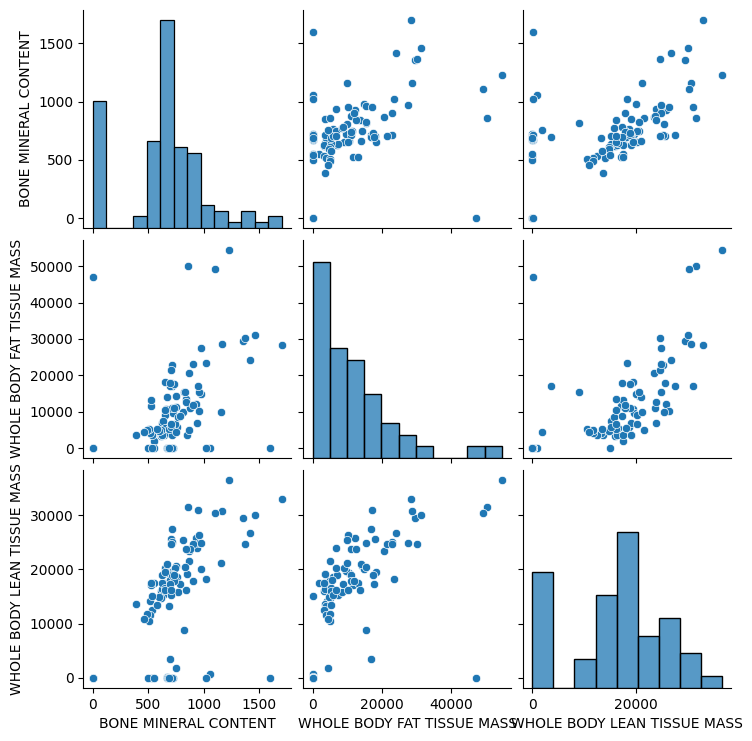

VISITINUM: 3


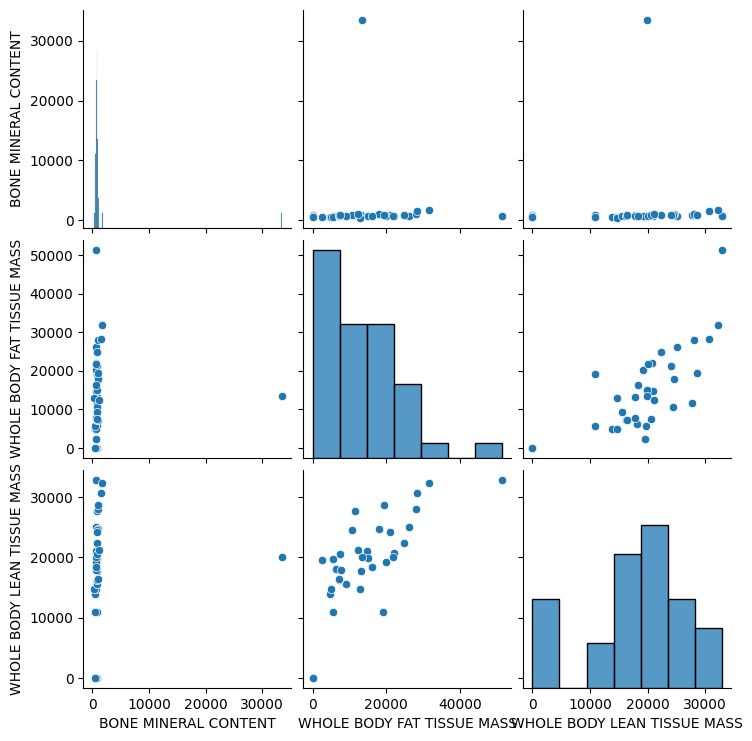

VISITINUM: 4


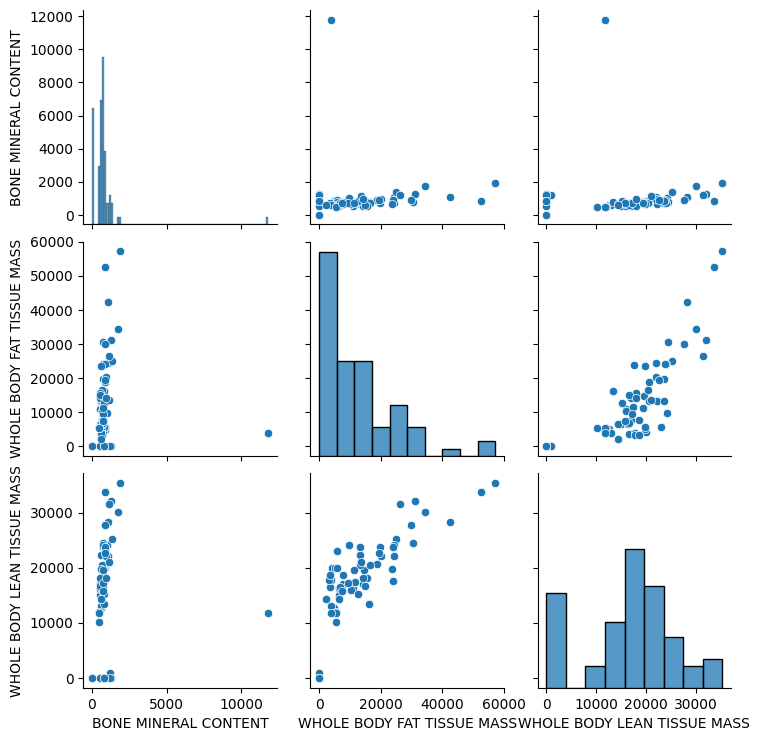

VISITINUM: 5


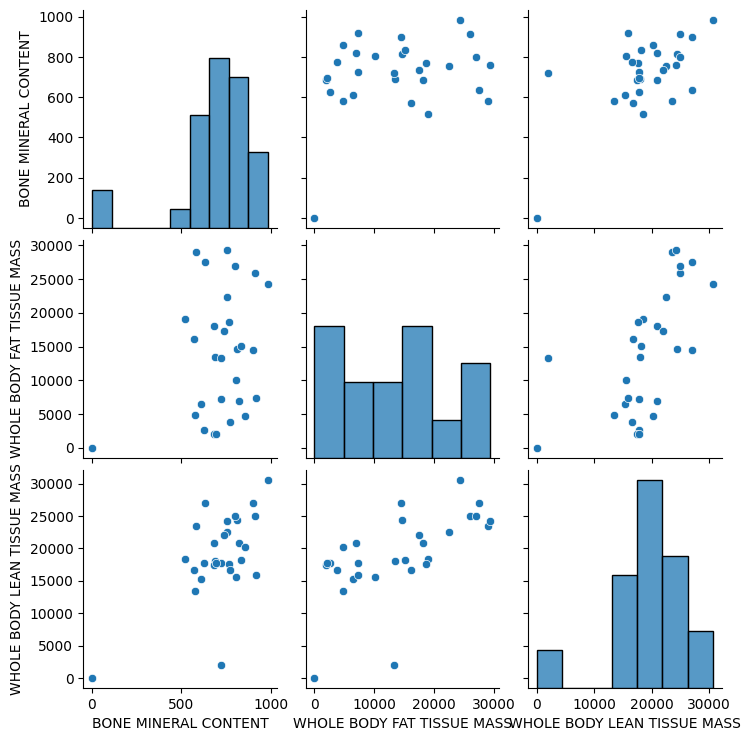

VISITINUM: 6


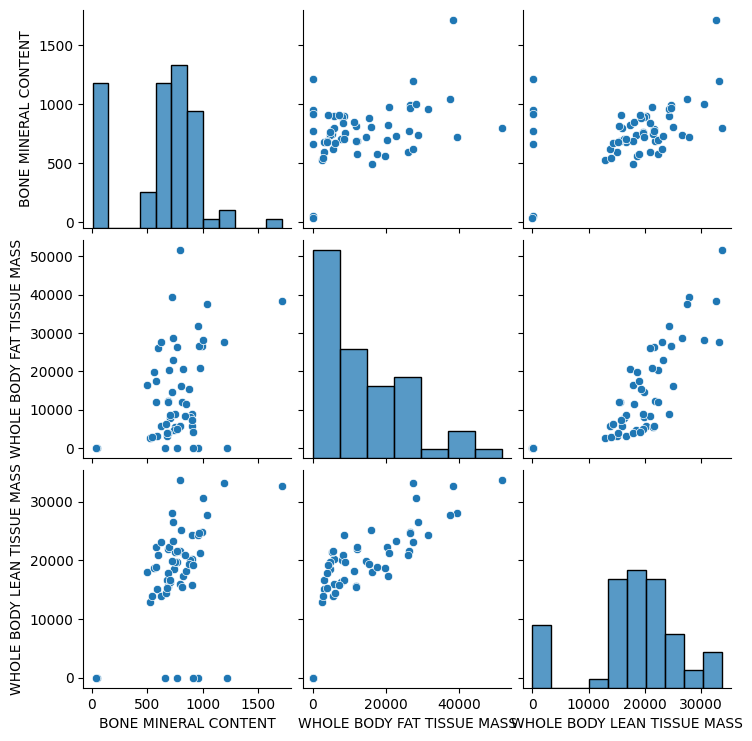

VISITINUM: 7


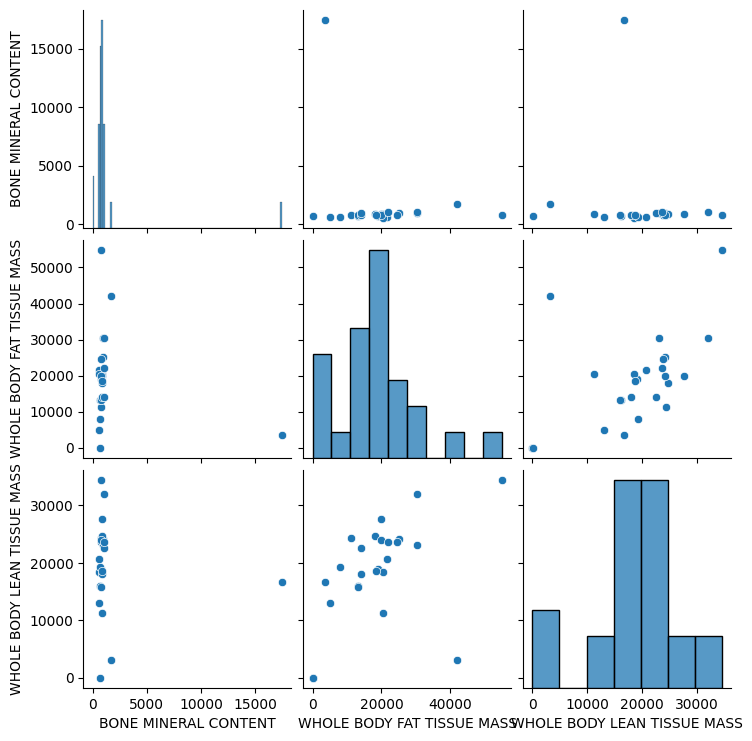

VISITINUM: 8


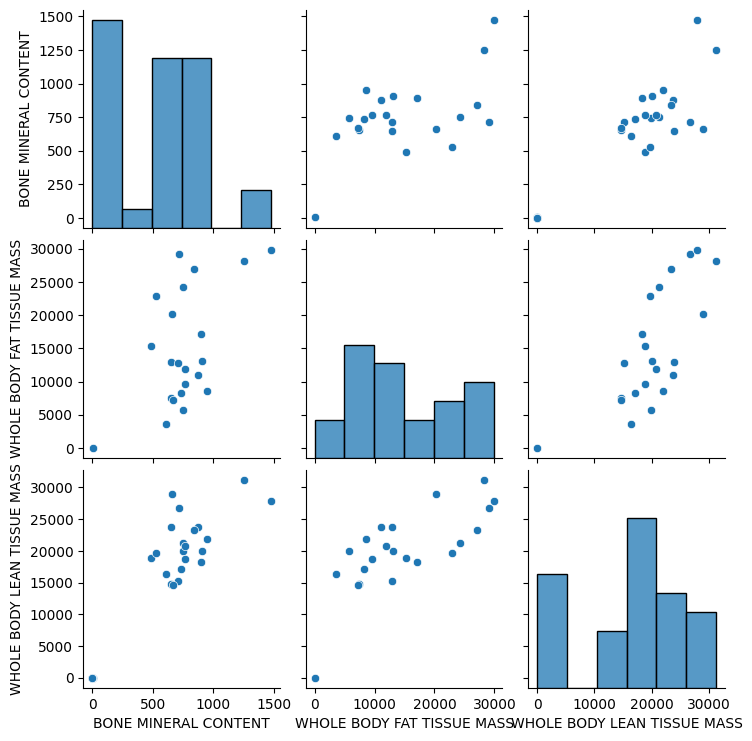

In [160]:
for visit in final_bm.groupby('VISITNUM'):
    
    print(f'VISITINUM: {visit[0]}')
    sns.pairplot(visit[1])
    plt.show()

In [161]:
measurements = measurements.join(final_bm, on=['USUBJID', 'VISITNUM'], how='outer')

In [ ]:
measurements.sort_index().head()

# `cv.csv` 

In [ ]:
cv = dataframes['cv']
cv = cv[cv.CVSTAT!='NOT DONE']
cv = cleaning_df(cv)
cv.head()

In [164]:
missing_values(cv)

,STUDYID,DOMAIN,USUBJID,VISITNUM,VISIT,CVSEQ,CVTESTCD,CVTEST,CVCAT,CVORRES,CVORRESU,CVSTRESC,CVSTRESN,CVSTRESU,CVDTC
Total,0,0,0,0,0,0,0,0,0,0,528,0,528,528,48
Percent(%),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,17.288802,0.0,17.288802,17.288802,1.571709
Types,object,object,object,int64,object,int64,object,object,object,object,object,object,float64,object,object


In [ ]:
final_cv = cv[['USUBJID', 'VISITNUM', 'CVTEST', 'CVSTRESN']]
final_cv['tests'] = final_cv[['CVTEST', 'CVSTRESN']].values.tolist() # we create a new column 'tests' that holds the test and its measurement as an array
final_cv = final_cv.drop(['CVTEST', 'CVSTRESN'], axis=1) # we drop the columns drom which we created the 'tests' column
final_cv = final_cv.groupby(['USUBJID', 'VISITNUM']).agg(list) # groupby subject id and visit and create a list of all the tests and their measurements
final_cv.head()

In [166]:
for test in cv.CVTEST.unique():
    final_cv[test] = final_cv.tests.apply(lambda row: make_col(row, test))
final_cv = final_cv.drop('tests', axis=1)

In [ ]:
final_cv.head()

In [168]:
measurements = measurements.join(final_cv, on=['USUBJID', 'VISITNUM'], how='outer')

In [ ]:
measurements.sort_index().head()

# `ms.csv` 

In [ ]:
ms = dataframes['ms']
ms = ms[ms.MSSTAT!='NOT DONE']
ms = cleaning_df(ms)
ms.head()

In [171]:
ms.MSORRESU.value_counts()

Lbs       6999
Newton    1279
Kg          65
Name: MSORRESU, dtype: int64

In [172]:
missing_values(ms)

,STUDYID,DOMAIN,USUBJID,VISITNUM,VISIT,MSSEQ,MSDOM,MSCAT,MSSCAT,MSTESTCD,MSTEST,MSORRES,MSORRESU,MSSTRESC,MSSTRESN,MSSTRESU,MSCO
Total,0,0,0,0,0,0,27017,0,13989,0,0,227,27250,330,5731,27335,26176
Percent(%),0.0,0.0,0.0,0.0,0.0,0.0,75.905375,0.0,39.302672,0.0,0.0,0.637766,76.559998,0.927149,16.101481,76.798809,73.542551
Types,object,object,object,int64,object,int64,object,object,object,object,object,object,object,object,float64,object,object


In [ ]:
ms_cols = ['USUBJID', 'VISITNUM', 'MSDOM', 'MSTEST', 'MSSTRESN'] 
ms_ts = ['MSTEST', 'MSSTRESN'] 
final_ms = preprocess(ms, ms_cols, ms_ts)
final_ms

In [174]:
for test in ms.MSTEST.unique():
    final_ms[test] = final_ms.tests.apply(lambda row: make_col(row, test))
final_ms = final_ms.drop('tests', axis=1)

In [175]:
final_ms['MSDOM'] = final_ms.MSDOM.apply(lambda x: x[0])

In [ ]:
final_ms.head()

In [177]:
measurements = join_dfs(final_ms, measurements)

In [ ]:
measurements.sort_index().head()

# `pe.csv` 

In [ ]:
pe = dataframes['pe']
pe.head()

In [180]:
missing_values(pe)

,STUDYID,DOMAIN,USUBJID,VISITNUM,VISIT,PESEQ,PETESTCD,PETEST,PEORRES,PESTRESC,PEABNSP
Total,0,0,0,0,0,0,0,0,110,110,14882
Percent(%),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.661415,0.661415,89.483495
Types,object,object,object,int64,object,int64,object,object,object,object,object


In [181]:
pe.PEABNSP.value_counts()

DMD                              110
ANSERINE GAIT                     64
DMD RELATED                       49
MUSCLE WEAKNESS                   30
SIGNS AND SYMPTOMS OF DMD         22
                                ... 
SHALLOW BREATHS BUT CLEAN          1
SEVERE WEAKNESS/ CONTRACTURES      1
SEVERE WEAKNESS QUADRIPLEGIA       1
RESTRICTIVE LUNG DISEASE           1
MACROGLOSSY                        1
Name: PEABNSP, Length: 1045, dtype: int64

In [ ]:
pe_cols = ['USUBJID', 'VISITNUM', 'PETESTCD', 'PESTRESC']
pe_ts = ['PETESTCD', 'PESTRESC']
final_pe = preprocess(pe, pe_cols, pe_ts)

In [183]:
for test in pe.PETESTCD.unique():
    final_pe[test] = final_pe.tests.apply(lambda row: make_col(row, test))
final_pe = final_pe.drop('tests', axis=1)

In [ ]:
final_pe.head()

In [185]:
measurements = join_dfs(final_pe, measurements)

In [ ]:
measurements.sort_index().head()

# `tt.csv` 

In [ ]:
tt = dataframes['tt']
tt = tt[tt.TTSTAT!='NOT DONE']
tt = cleaning_df(tt)
tt.head()

In [188]:
missing_values(tt)

,STUDYID,DOMAIN,USUBJID,VISITNUM,VISIT,TTSEQ,TTTEST,TTTESTCD,TTCAT,TTORRES,TTORRESU,TTSTRESC,TTSTRESU,TTDUR,TTCOMP,TTDIS,TTDISU
Total,0,0,0,0,0,0,0,0,0,253,12549,253,12549,267,10566,13509,13509
Percent(%),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.871994,92.852386,1.871994,92.852386,1.975583,78.1798,99.955605,99.955605
Types,object,object,object,int64,object,int64,object,object,object,object,object,object,object,object,object,float64,object


In [189]:
tt.TTCAT.value_counts()

6-MINUTE WALKING DISTANCE    3896
10 METER WALK/ RUN TEST      2982
4- STAIR CLIMB- ASCENT       2868
4- STAIR CLIMB- DESCENT      2868
RISE FROM FLOOR               901
Name: TTCAT, dtype: int64

### 6MWD

In [ ]:
tt_6mwd = tt[tt.TTCAT=='6-MINUTE WALKING DISTANCE']
tt_6mwd.head()

In [ ]:
tt_6mwd = cleaning_df(tt_6mwd)
tt_6mwd.head()

In [ ]:
tt_6mwd_cols = ['USUBJID', 'VISITNUM', 'TTTESTCD', 'TTSTRESC', 'TTDUR']
tt_6mwd_ts = ['TTTESTCD', 'TTSTRESC', 'TTDUR']
final_tt_6mwd = preprocess(tt_6mwd, tt_6mwd_cols, tt_6mwd_ts)

In [193]:
for test in tt_6mwd.TTTESTCD.unique():
    final_tt_6mwd[test] = final_tt_6mwd.tests.apply(lambda row: make_col(row, test))
final_tt_6mwd = final_tt_6mwd.drop('tests', axis=1)

In [ ]:
final_tt_6mwd

In [195]:
final_tt_6mwd = final_tt_6mwd.rename(columns={'AIDS': '6MWD_AIDS',
                              'SHOES': '6MWD_SHOES',
                              'DISWLK': '6MWD_DISWLK', 
                              'NOFALL': '6MWD_NOFALL'})

In [196]:
measurements = join_dfs(final_tt_6mwd, measurements)

### 10M Walk/Run Test

In [197]:
tt_10mwr = tt[tt.TTCAT=='10 METER WALK/ RUN TEST']
# tt_10mwr.head()

In [198]:
tt_10mwr = cleaning_df(tt_10mwr)
tt_10mwr = tt_10mwr[tt.TTCOMP=='COMPLETED']

Boolean Series key will be reindexed to match DataFrame index.


In [ ]:
tt_10mwr_cols = ['USUBJID', 'VISITNUM', 'TTTESTCD', 'TTSTRESC', 'TTDUR']
tt_10mwr_ts = ['TTTESTCD', 'TTSTRESC', 'TTDUR']
final_tt_10mwr = preprocess(tt_10mwr, tt_10mwr_cols, tt_10mwr_ts)

In [200]:
for test in tt_10mwr.TTTESTCD.unique():
    final_tt_10mwr[test] = final_tt_10mwr.tests.apply(lambda row: make_col(row, test))
final_tt_10mwr = final_tt_10mwr.drop('tests', axis=1)

In [ ]:
final_tt_10mwr

In [202]:
final_tt_10mwr = final_tt_10mwr.rename(columns={'AIDS': '10MWR_AIDS', 
                                              'SHOES': '10MWR_SHOES'})

In [203]:
measurements = join_dfs(final_tt_10mwr, measurements)

### 4 STAIR CLIMB Ascend

In [ ]:
tt_4sca = tt[tt.TTCAT=='4- STAIR CLIMB- ASCENT']
tt_4sca = cleaning_df(tt_4sca)
tt_4sca.head()

In [ ]:
tt_4sca_cols = ['USUBJID', 'VISITNUM', 'TTTESTCD', 'TTSTRESC', 'TTDUR']
tt_4sca_ts = ['TTTESTCD', 'TTSTRESC', 'TTDUR']
final_tt_4sca = preprocess(tt_4sca, tt_4sca_cols, tt_4sca_ts)

In [206]:
for test in tt_4sca.TTTESTCD.unique():
    final_tt_4sca[test] = final_tt_4sca.tests.apply(lambda row: make_col(row, test))
final_tt_4sca = final_tt_4sca.drop('tests', axis=1)

In [ ]:
final_tt_4sca

In [208]:
final_tt_4sca = final_tt_4sca.rename(columns={'AIDS': '4SCA_AIDS', 
                                              'SHOES': '4SCA_SHOES',
                                              '4-AGRAD': '4SCA_4-AGRAD'})

In [209]:
measurements = join_dfs(final_tt_4sca, measurements)

### 4 STAIR CLIMB Descend

In [ ]:
tt_4scd = tt[tt.TTCAT=='4- STAIR CLIMB- DESCENT']
tt_4scd = cleaning_df(tt_4scd)
tt_4scd.head()

In [ ]:
tt_4scd_cols = ['USUBJID', 'VISITNUM', 'TTTESTCD', 'TTSTRESC', 'TTDUR']
tt_4scd_ts = ['TTTESTCD', 'TTSTRESC', 'TTDUR']
final_tt_4scd = preprocess(tt_4scd, tt_4scd_cols, tt_4scd_ts)

In [212]:
for test in tt_4scd.TTTESTCD.unique():
    final_tt_4scd[test] = final_tt_4scd.tests.apply(lambda row: make_col(row, test))
final_tt_4scd = final_tt_4scd.drop('tests', axis=1)

In [ ]:
final_tt_4scd

In [214]:
final_tt_4scd = final_tt_4scd.rename(columns={'AIDS': '4SCD_AIDS', 
                                              'SHOES': '4SCD_SHOES',
                                              '4-AGRAD': '4SCD_4-AGRAD'})

In [215]:
measurements = join_dfs(final_tt_4scd, measurements)

### Rise from floor

In [ ]:
tt_rff = tt[tt.TTCAT=='RISE FROM FLOOR']
tt_rff = cleaning_df(tt_rff)
tt_rff.head()

In [ ]:
tt_rff_cols = ['USUBJID', 'VISITNUM', 'TTTESTCD', 'TTSTRESC', 'TTDUR']
tt_rff_ts = ['TTTESTCD', 'TTSTRESC', 'TTDUR']
final_tt_rff = preprocess(tt_rff, tt_rff_cols, tt_rff_ts)

In [218]:
for test in tt_rff.TTTESTCD.unique():
    final_tt_rff[test] = final_tt_rff.tests.apply(lambda row: make_col(row, test))
final_tt_rff = final_tt_rff.drop('tests', axis=1)

In [ ]:
final_tt_rff

In [220]:
final_tt_rff = final_tt_rff.rename(columns={'GRAD': 'RISE_FROM_FLOOR'})

In [221]:
measurements = join_dfs(final_tt_rff, measurements)

# `re.csv` 

In [ ]:
re = dataframes['re']
re = re[re.RESTAT!='NOT DONE']
re = cleaning_df(re)
re.head()

In [223]:
re.RETEST.value_counts()

FORCED EXPIRATORY VOLUME            1178
FEV1 - % OF PREDICTED               1178
FORCED VITAL CAPACITY               1178
FVC - % OF PREDICTED                1178
MAXIMAL EXPIRATORY PRESSURE         1178
MAXIMAL INSPIRATORY PRESSURE        1178
PEAK COUGH FLOW                     1178
PEAK FLOW                           1178
PF- % OF PREDICTED                  1178
SNIFF NASAL INSPIRATORY PRESSURE    1178
Name: RETEST, dtype: int64

In [224]:
missing_values(re)

,STUDYID,DOMAIN,USUBJID,VISITNUM,VISIT,RESEQ,RETESTCD,RETEST,REORRES,REORRESU,RESTRESC,RESTRESN,RESTRESU,REDTC
Total,0,0,0,0,0,0,0,0,2737,2739,2737,2737,2739,60
Percent(%),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,23.234295,23.251273,23.234295,23.234295,23.251273,0.509338
Types,object,object,object,int64,object,int64,object,object,float64,object,float64,float64,object,object


In [ ]:
re_cols = ['USUBJID', 'VISITNUM', 'RETESTCD', 'RESTRESN']
re_ts = ['RETESTCD', 'RESTRESN']
final_re = preprocess(re, re_cols, re_ts)

In [226]:
for test in re.RETESTCD.unique():
    final_re[test] = final_re.tests.apply(lambda row: make_col(row, test))
final_re = final_re.drop('tests', axis=1)

In [ ]:
final_re.head()

In [228]:
final_re.reset_index('VISITNUM').loc[final_re[final_re['FVC%']<60][['FVC%']].reset_index().USUBJID.tolist()].index.unique().shape

(60,)

In [229]:
measurements = join_dfs(final_re, measurements)

In [ ]:
measurements.sort_index().head()

# `mt.csv`

In [ ]:
mt = dataframes['mt']
mt = mt[mt.MTSTAT!='NOT DONE']
mt = cleaning_df(mt)
mt.head()

In [232]:
missing_values(mt)

,STUDYID,DOMAIN,USUBJID,VISITNUM,VISIT,MTSEQ,MTCAT,MTDTC,MTDOM,MTWDTH,MTWDTHU,MTW,MTWU,MTSP,MTCOM,MTTOOL,MTSENSU,MTCYLUSD,MTSUP,MTMETUSD
Total,0,0,0,0,0,0,0,0,1116,1116,1116,60,507,495,1048,40,1329,1327,1331,1327
Percent(%),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,62.731872,62.731872,62.731872,3.372681,28.499157,27.824621,58.9095,2.248454,74.70489,74.592468,74.817313,74.592468
Types,object,object,object,int64,object,int64,object,object,object,float64,object,float64,object,object,object,float64,object,object,object,object


In [233]:
mt[(mt.VISITNUM==2) & (mt.MTCAT=='MYOPINCH')].index.unique().shape

(69,)

# `sv.csv`  

In [ ]:
sv = dataframes['sv']
sv.head()

In [235]:
missing_values(sv)

,STUDYID,DOMAIN,USUBJID,VISITNUM,VISIT,SVSEQ,SVSTDTC,SVPAGRP,SVPGWLK
Total,0,0,0,0,0,0,0,26,428
Percent(%),0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.74146,28.667113
Types,object,object,object,int64,object,int64,object,object,object


In [ ]:
final_sv = sv[['USUBJID', 'VISITNUM', 'SVPAGRP', 'SVPGWLK', 'SVSTDTC']]
final_sv = final_sv.rename(columns={'SVPAGRP':'MOTOR_STATE', 'SVPGWLK':'WALK75M', 'SVSTDTC':'MOTOR_STATE_DATE'})
final_sv = final_sv.set_index(['USUBJID', 'VISITNUM'])
final_sv.head()

In [237]:
final_sv.MOTOR_STATE.value_counts()

AMBULANT        1064
NON-AMBULANT     403
Name: MOTOR_STATE, dtype: int64

In [ ]:
for i in final_sv.groupby('USUBJID'):
    print(i[1])

In [239]:
measurements = join_dfs(final_sv, measurements)

In [ ]:
measurements.sort_index().head()

# `vs.csv` 

In [ ]:
vs = dataframes['vs']
vs.head()

In [242]:
missing_values(vs)

,STUDYID,DOMAIN,USUBJID,VISITNUM,VISIT,VSSEQ,VSTESTCD,VSTEST,VSORRES,VSORRESU,VSSTRESC,VSSTRESN,VSSTRESU
Total,0,0,0,0,0,0,0,0,0,1346,0,0,1346
Percent(%),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14.568676,0.0,0.0,14.568676
Types,object,object,object,int64,object,int64,object,object,float64,object,float64,float64,object


In [ ]:
vs_cols = ['USUBJID', 'VISITNUM', 'VSTESTCD', 'VSSTRESN']
vs_ts = ['VSTESTCD', 'VSSTRESN']
final_vs = preprocess(vs, vs_cols, vs_ts)

In [244]:
for test in vs.VSTESTCD.unique():
    final_vs[test] = final_vs.tests.apply(lambda row: make_col(row, test))
final_vs = final_vs.drop('tests', axis=1)

In [ ]:
final_vs.head()

In [246]:
measurements = join_dfs(final_vs, measurements)

In [ ]:
measurements.sort_index()

# **File with 8 visits**

# `co.csv` 

In [ ]:
co = dataframes['co']
co.head()

In [249]:
missing_values(co)

,STUDYID,DOMAIN,USUBJID,VISITNUM,VISIT,FormRep,ItemSet,COANTL,CONAME,COVAL,COVAL1
Total,0,0,0,0,0,63791,62323,0,0,673,64083
Percent(%),0.0,0.0,0.0,0.0,0.0,99.4869,97.197442,0.0,0.0,1.049595,99.942296
Types,object,object,object,int64,object,float64,float64,object,object,object,object


In [ ]:
eurofins = dataframes['eurofins']
eurofins

## Final Dataset Generation

In [251]:
final_dataset = measurements.join(dataset, on='USUBJID')

In [252]:
final_dataset.MOTOR_STATE.value_counts()

AMBULANT        1125
NON-AMBULANT     422
Name: MOTOR_STATE, dtype: int64

In [253]:
final_dataset.shape

(1583, 198)

In [254]:
measurements.shape

(1583, 170)

In [255]:
dataset.shape

(269, 28)

In [256]:
final_dataset.shape

(1583, 198)

In [ ]:
final_dataset.sort_index()

In [258]:
final_dataset.to_csv('datasets/01-dataset.csv')